# Тема 2. Онтологии и связанные данные
## Семинар 2. Формализация RDFS/OWL, проверка SHACL и публикация Linked Data

In [1]:
%pip install -q rdflib pyshacl

from IPython.display import display, HTML, SVG
from pathlib import Path
from urllib.parse import quote
import html as _html

import rdflib
from rdflib import Graph, Namespace, URIRef, Literal, BNode
from rdflib.namespace import RDF, RDFS, OWL, XSD
from pyshacl import validate as shacl_validate

UNI = Namespace("https://example.org/university/")
SCHEMA = Namespace("https://schema.org/")
FOAF = Namespace("http://xmlns.com/foaf/0.1/")
DCTERMS = Namespace("http://purl.org/dc/terms/")
SKOS = Namespace("http://www.w3.org/2004/02/skos/core#")
SH = Namespace("http://www.w3.org/ns/shacl#")

print("RDFLib:", rdflib.__version__)
print("pySHACL: библиотека подключена")

display(HTML(r"""
<style>
.output_scroll,
.jp-OutputArea-output,
.jp-RenderedSVG,
.output_subarea,
.jp-OutputArea-child {
    max-height: none !important;
    height: auto !important;
    overflow-y: visible !important;
}
.jp-RenderedSVG svg,
.output_svg svg,
svg {
    max-width: 100% !important;
    height: auto !important;
}
</style>
"""))

def bind_common(graph):
    for prefix, ns in [
        ("uni", UNI), ("rdf", RDF), ("rdfs", RDFS), ("owl", OWL), ("xsd", XSD),
        ("schema", SCHEMA), ("foaf", FOAF), ("dcterms", DCTERMS),
        ("skos", SKOS), ("sh", SH)
    ]:
        graph.bind(prefix, ns)
    return graph

def term_text(term, graph=None):
    if term is None:
        return ""
    if isinstance(term, URIRef) and graph is not None:
        try:
            return graph.namespace_manager.qname(term)
        except Exception:
            return str(term)
    return str(term)

def show_table(headers, rows):
    head = "".join(f"<th>{_html.escape(str(h))}</th>" for h in headers)
    body = []
    for row in rows:
        body.append("<tr>" + "".join(f"<td>{_html.escape(str(v))}</td>" for v in row) + "</tr>")
    display(HTML(
        '<div style="overflow-x:auto;overflow-y:visible;margin:8px 0 18px 0;">'
        '<table style="border-collapse:collapse;width:100%;table-layout:auto;font-size:14px;">'
        '<thead><tr>' + head + '</tr></thead>'
        '<tbody>' + "".join(body) + '</tbody></table></div>'
        '<style>'
        'table th,table td{border:1px solid #bbb;padding:7px 9px;vertical-align:top;'
        'white-space:normal;overflow-wrap:anywhere;line-height:1.35;}'
        'table th{font-weight:600;background:#f5f5f5;}'
        '</style>'
    ))

def show_sparql_result(graph, query, max_rows=40):
    result = graph.query(query)
    if getattr(result, "type", None) == "ASK":
        print("Результат ASK:", bool(result.askAnswer))
        return None
    if getattr(result, "type", None) in ("CONSTRUCT", "DESCRIBE"):
        out_graph = result.graph
        bind_common(out_graph)
        print("Получено RDF-троек:", len(out_graph))
        print(out_graph.serialize(format="turtle"))
        return None
    headers = [str(v) for v in result.vars]
    rows = []
    for idx, row in enumerate(result):
        if idx >= max_rows:
            break
        rows.append([term_text(v, graph) for v in row])
    show_table(headers, rows)
    if not rows:
        print("Запрос выполнен, строк результата нет.")
    return None

def parse_turtle_text(text):
    g = bind_common(Graph())
    g.parse(data=text, format="turtle")
    return g

def clone_graph(source):
    g = bind_common(Graph())
    for triple in source:
        g.add(triple)
    return g

def download_button(filename, text, label=None, mime="text/plain"):
    label = label or f"Скачать {filename}"
    href = "data:" + mime + ";charset=utf-8," + quote(text)
    display(HTML(
        '<a download="' + _html.escape(filename) + '" href="' + href + '" '
        'style="display:inline-block;padding:7px 11px;margin:3px 6px 3px 0;'
        'border:1px solid #777;border-radius:6px;text-decoration:none;">'
        + _html.escape(label) + '</a>'
    ))



[notice] A new release of pip is available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


RDFLib: 7.6.0
pySHACL: библиотека подключена


In [2]:
ONTOLOGY_TEMPLATE = r"""@prefix uni: <https://example.org/university/> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix schema: <https://schema.org/> .
@prefix foaf: <http://xmlns.com/foaf/0.1/> .
@prefix dcterms: <http://purl.org/dc/terms/> .

uni:ontology a owl:Ontology ;
    dcterms:title "Учебная онтология университета"@ru ;
    dcterms:title "University Teaching Ontology"@en ;
    dcterms:description "Классы и свойства для описания курсов, программ, людей и кафедр"@ru ;
    dcterms:creator "Учебная группа"@ru ;
    dcterms:modified "2026-07-14"^^xsd:date ;
    owl:versionInfo "1.0" .

uni:Person a rdfs:Class ;
    rdfs:subClassOf schema:Person , foaf:Person ;
    rdfs:label "Человек"@ru , "Person"@en ;
    rdfs:comment "Физическое лицо, участвующее в деятельности университета"@ru ;
    rdfs:isDefinedBy uni:ontology .

uni:Student a rdfs:Class ;
    rdfs:subClassOf uni:Person ;
    rdfs:label "Студент"@ru , "Student"@en ;
    rdfs:comment "Лицо, зачисленное на образовательную программу"@ru ;
    rdfs:isDefinedBy uni:ontology .

uni:Teacher a rdfs:Class ;
    rdfs:subClassOf uni:Person ;
    rdfs:label "Преподаватель"@ru , "Teacher"@en ;
    rdfs:comment "Лицо, ведущее учебный курс или его проведение"@ru ;
    rdfs:isDefinedBy uni:ontology .

uni:Organization a rdfs:Class ;
    rdfs:subClassOf schema:Organization ;
    rdfs:label "Организация"@ru , "Organization"@en ;
    rdfs:isDefinedBy uni:ontology .

uni:University a rdfs:Class ;
    rdfs:subClassOf uni:Organization , schema:CollegeOrUniversity ;
    rdfs:label "Университет"@ru , "University"@en ;
    rdfs:isDefinedBy uni:ontology .

uni:Department a rdfs:Class ;
    rdfs:subClassOf uni:Organization ;
    rdfs:label "Кафедра"@ru , "Department"@en ;
    rdfs:isDefinedBy uni:ontology .

uni:EducationalEntity a rdfs:Class ;
    rdfs:label "Образовательная сущность"@ru , "Educational entity"@en ;
    rdfs:isDefinedBy uni:ontology .

uni:Course a rdfs:Class ;
    rdfs:subClassOf uni:EducationalEntity , schema:Course ;
    rdfs:label "Учебный курс"@ru , "Course"@en ;
    rdfs:comment "Абстрактное описание учебного содержания"@ru ;
    rdfs:isDefinedBy uni:ontology .

uni:CourseInstance a rdfs:Class ;
    rdfs:subClassOf uni:EducationalEntity , schema:CourseInstance ;
    rdfs:label "Проведение курса"@ru , "Course instance"@en ;
    rdfs:comment "Конкретная реализация курса в учебном периоде"@ru ;
    rdfs:isDefinedBy uni:ontology .

uni:EducationalProgram a rdfs:Class ;
    rdfs:subClassOf uni:EducationalEntity ;
    rdfs:label "Образовательная программа"@ru , "Educational program"@en ;
    rdfs:isDefinedBy uni:ontology .

uni:Enrollment a rdfs:Class ;
    rdfs:label "Зачисление на проведение курса"@ru , "Enrollment"@en ;
    rdfs:comment "Связующая сущность между студентом и проведением курса"@ru ;
    rdfs:isDefinedBy uni:ontology .

uni:participatesInLearning a rdf:Property ;
    rdfs:domain uni:Person ;
    rdfs:range uni:EducationalEntity ;
    rdfs:label "участвует в обучении"@ru .

uni:studiesCourse a owl:ObjectProperty ;
    rdfs:subPropertyOf uni:participatesInLearning ;
    rdfs:domain uni:Student ;
    rdfs:range uni:Course ;
    rdfs:label "изучает курс"@ru .

uni:teachesCourse a owl:ObjectProperty ;
    rdfs:subPropertyOf uni:participatesInLearning ;
    rdfs:domain uni:Teacher ;
    rdfs:range uni:Course ;
    rdfs:label "ведёт курс"@ru ;
    owl:inverseOf uni:isTaughtBy .

uni:isTaughtBy a owl:ObjectProperty ;
    rdfs:domain uni:Course ;
    rdfs:range uni:Teacher ;
    rdfs:label "ведётся преподавателем"@ru .

uni:hasCourseInstance a owl:ObjectProperty ;
    rdfs:subPropertyOf schema:hasCourseInstance ;
    rdfs:domain uni:Course ;
    rdfs:range uni:CourseInstance ;
    rdfs:label "имеет проведение"@ru .

uni:partOfProgram a owl:ObjectProperty ;
    rdfs:domain uni:Course ;
    rdfs:range uni:EducationalProgram ;
    rdfs:label "входит в программу"@ru .

uni:memberOfDepartment a owl:ObjectProperty ;
    rdfs:domain uni:Person ;
    rdfs:range uni:Department ;
    rdfs:label "относится к кафедре"@ru .

uni:providedByDepartment a owl:ObjectProperty ;
    rdfs:domain uni:Course ;
    rdfs:range uni:Department ;
    rdfs:label "предоставляется кафедрой"@ru .

uni:partOfUniversity a owl:ObjectProperty ;
    rdfs:domain uni:Department ;
    rdfs:range uni:University ;
    rdfs:label "входит в университет"@ru .

uni:hasEnrollment a owl:ObjectProperty ;
    rdfs:domain uni:Student ;
    rdfs:range uni:Enrollment ;
    rdfs:label "имеет зачисление"@ru .

uni:forCourseInstance a owl:ObjectProperty ;
    rdfs:domain uni:Enrollment ;
    rdfs:range uni:CourseInstance ;
    rdfs:label "относится к проведению курса"@ru .

uni:fullName a owl:DatatypeProperty ;
    rdfs:subPropertyOf schema:name ;
    rdfs:domain uni:Person ;
    rdfs:range rdf:langString ;
    rdfs:label "полное имя"@ru .

uni:courseCode a owl:DatatypeProperty ;
    rdfs:subPropertyOf schema:courseCode ;
    rdfs:domain uni:Course ;
    rdfs:range xsd:string ;
    rdfs:label "код курса"@ru .

uni:credits a owl:DatatypeProperty ;
    rdfs:domain uni:Course ;
    rdfs:range xsd:decimal ;
    rdfs:label "зачётные единицы"@ru .

uni:startDate a owl:DatatypeProperty ;
    rdfs:subPropertyOf schema:startDate ;
    rdfs:domain uni:CourseInstance ;
    rdfs:range xsd:date ;
    rdfs:label "дата начала"@ru .

uni:academicYear a owl:DatatypeProperty ;
    rdfs:domain uni:CourseInstance ;
    rdfs:range xsd:gYear ;
    rdfs:label "учебный год"@ru .

uni:enrollmentStatus a owl:DatatypeProperty ;
    rdfs:domain uni:Enrollment ;
    rdfs:range xsd:string ;
    rdfs:label "статус зачисления"@ru .

uni:Person owl:disjointWith uni:Course .
"""

DATA_TEMPLATE = r"""@prefix uni: <https://example.org/university/> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix schema: <https://schema.org/> .
@prefix dcterms: <http://purl.org/dc/terms/> .

uni:ExampleUniversity a uni:University ;
    rdfs:label "Примерный университет"@ru , "Example University"@en ;
    schema:url <https://www.example.edu/> .

uni:AIDepartment a uni:Department ;
    rdfs:label "Кафедра искусственного интеллекта"@ru ;
    uni:partOfUniversity uni:ExampleUniversity .

uni:DataDepartment a uni:Department ;
    rdfs:label "Кафедра инженерии данных"@ru ;
    uni:partOfUniversity uni:ExampleUniversity .

uni:AppliedInformatics a uni:EducationalProgram ;
    rdfs:label "Прикладная информатика"@ru .

uni:DataEngineering a uni:EducationalProgram ;
    rdfs:label "Инженерия данных"@ru .

uni:SemTech a uni:Course ;
    rdfs:label "Семантические технологии"@ru , "Semantic Technologies"@en ;
    uni:courseCode "ST-201" ;
    uni:credits "3"^^xsd:decimal ;
    uni:partOfProgram uni:AppliedInformatics ;
    uni:providedByDepartment uni:AIDepartment ;
    dcterms:subject <http://dbpedia.org/resource/Semantic_Web> .

uni:KnowledgeGraphs a uni:Course ;
    rdfs:label "Графы знаний"@ru , "Knowledge Graphs"@en ;
    uni:courseCode "KG-301" ;
    uni:credits "4"^^xsd:decimal ;
    uni:partOfProgram uni:DataEngineering ;
    uni:providedByDepartment uni:DataDepartment ;
    dcterms:subject <http://dbpedia.org/resource/Knowledge_graph> .

uni:SemTech2026Autumn a uni:CourseInstance ;
    rdfs:label "Семантические технологии, осень 2026"@ru ;
    uni:startDate "2026-09-01"^^xsd:date ;
    uni:academicYear "2026"^^xsd:gYear .

uni:KnowledgeGraphs2027Spring a uni:CourseInstance ;
    rdfs:label "Графы знаний, весна 2027"@ru ;
    uni:startDate "2027-02-08"^^xsd:date ;
    uni:academicYear "2027"^^xsd:gYear .

uni:SemTech uni:hasCourseInstance uni:SemTech2026Autumn .
uni:KnowledgeGraphs uni:hasCourseInstance uni:KnowledgeGraphs2027Spring .

uni:Anna a uni:Student ;
    uni:fullName "Анна Смирнова"@ru ;
    uni:studiesCourse uni:SemTech ;
    uni:memberOfDepartment uni:AIDepartment .

uni:Ivan a uni:Student ;
    uni:fullName "Иван Орлов"@ru ;
    uni:studiesCourse uni:SemTech , uni:KnowledgeGraphs ;
    uni:memberOfDepartment uni:DataDepartment .

uni:Petrova a uni:Teacher ;
    uni:fullName "Елена Петрова"@ru ;
    uni:teachesCourse uni:SemTech ;
    uni:memberOfDepartment uni:AIDepartment .

uni:Sidorov a uni:Teacher ;
    uni:fullName "Максим Сидоров"@ru ;
    uni:teachesCourse uni:KnowledgeGraphs ;
    uni:memberOfDepartment uni:DataDepartment .

uni:AnnaSemTechEnrollment a uni:Enrollment ;
    uni:forCourseInstance uni:SemTech2026Autumn ;
    uni:enrollmentStatus "active" .

uni:Anna uni:hasEnrollment uni:AnnaSemTechEnrollment .
"""



### Исходные файлы и организация работы

Практическая работа начинается с файла `ontology_draft.ttl`, содержащего концептуальную модель выбранной предметной области. Этот файл используется как исходное описание классов, свойств и связей, но ещё не является окончательной формальной схемой.

В ходе занятия на его основе формируются три самостоятельных файла:

```text
ontology_draft.ttl  -> исходная концептуальная модель
ontology.ttl        -> формальная схема RDFS/OWL
data.ttl            -> экземпляры и факты предметной области
shapes.ttl          -> требования SHACL к проверяемым данным
```

Основная задача состоит в переходе от концептуального описания к формальной семантике, логическому выводу, валидации и публикации RDF-данных.

Следующая ячейка проверяет наличие `ontology_draft.ttl` рядом с notebook и корректность его синтаксиса средствами RDFLib.


In [3]:
def check_turtle_file(filename):
    p = Path(filename)
    if not p.exists():
        print(f"{filename}: файл не найден. Разместите его рядом с notebook перед началом работы с исходной моделью.")
        return None
    try:
        g = bind_common(Graph())
        g.parse(str(p), format="turtle")
        print(f"{filename}: OK, RDFLib прочитал {len(g)} троек.")
        return g
    except Exception as exc:
        print(f"{filename}: ОШИБКА")
        print(type(exc).__name__ + ":", exc)
        return None

_ = check_turtle_file("ontology_draft.ttl")


ontology_draft.ttl: OK, RDFLib прочитал 148 троек.


## 1. Формальная семантика RDFS

RDF позволяет записывать факты в виде троек, однако сами по себе тройки не задают формальные отношения между классами и свойствами. RDF Schema (RDFS) дополняет RDF словарём средств, с помощью которых описываются иерархии классов и свойств, области определения и значений свойств, а также аннотации терминов.

### 1.1. Метаданные формальной онтологии

Формальная онтология должна быть представлена самостоятельным RDF-ресурсом, для которого можно указать название, автора, версию и дату изменения.

Рассмотрим фрагмент Turtle:

```turtle
@prefix uni: <https://example.org/university/> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix dcterms: <http://purl.org/dc/terms/> .

uni:ontology a owl:Ontology ;
    dcterms:title "Онтология учебных курсов"@ru ;
    dcterms:creator "Учебная группа"@ru ;
    owl:versionInfo "1.0" ;
    dcterms:modified "2026-07-14"^^xsd:date .
```

`owl:versionInfo` содержит информацию о версии модели, а `dcterms:modified` задаёт дату изменения как типизированный литерал `xsd:date`.


In [4]:
metadata_graph = parse_turtle_text(r"""
@prefix uni: <https://example.org/university/> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix dcterms: <http://purl.org/dc/terms/> .

uni:ontology a owl:Ontology ;
    dcterms:title "Онтология учебных курсов"@ru ;
    dcterms:creator "Учебная группа"@ru ;
    owl:versionInfo "1.0" ;
    dcterms:modified "2026-07-14"^^xsd:date .
""")

show_sparql_result(metadata_graph, """
PREFIX uni: <https://example.org/university/>
PREFIX owl: <http://www.w3.org/2002/07/owl#>
PREFIX dcterms: <http://purl.org/dc/terms/>

SELECT ?title ?creator ?version ?modified
WHERE {
  uni:ontology dcterms:title ?title ;
               dcterms:creator ?creator ;
               owl:versionInfo ?version ;
               dcterms:modified ?modified .
}
""")


title,creator,version,modified
Онтология учебных курсов,Учебная группа,1.0,2026-07-14


### 1.2. Наследование типов через `rdfs:subClassOf`

`rdfs:subClassOf` задаёт отношение включения между классами. Если класс $A$ является подклассом класса $B$, каждый экземпляр $A$ одновременно является экземпляром $B$:

$$
A \subseteq B,\qquad x \in A \Longrightarrow x \in B
$$

Отношение подкласса транзитивно. Если `GraduateStudent` является подклассом `Student`, а `Student` является подклассом `Person`, то любой экземпляр `GraduateStudent` относится также к `Student` и `Person`.

Рассмотрим цепочку классов:

```text
GraduateStudent -> Student -> Person
```

и экземпляр `uni:Anna` типа `GraduateStudent`


In [5]:
rdfs_class_demo = parse_turtle_text(r"""
@prefix uni: <https://example.org/university/> .
@prefix rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .

uni:Person a rdfs:Class .
uni:Student a rdfs:Class ; rdfs:subClassOf uni:Person .
uni:GraduateStudent a rdfs:Class ; rdfs:subClassOf uni:Student .
uni:Anna a uni:GraduateStudent .
""")

show_sparql_result(rdfs_class_demo, """
PREFIX uni: <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?child ?parent
WHERE { ?child rdfs:subClassOf+ ?parent }
ORDER BY ?child ?parent
""")


child,parent
uni:GraduateStudent,uni:Person
uni:GraduateStudent,uni:Student
uni:Student,uni:Person


### 1.3. Иерархия свойств через `rdfs:subPropertyOf`

`rdfs:subPropertyOf` используется для формального включения одного отношения в другое. Если каждое утверждение со свойством $p_1$ одновременно является корректным утверждением со свойством $p_2$, то $p_1$ можно объявить подсвойством $p_2$.

Рассмотрим пример:

```turtle
uni:studiesCourse rdfs:subPropertyOf uni:participatesInLearning .
```

Формальная семантика этого отношения:

$$
p_1 \sqsubseteq p_2,\qquad p_1(s,o) \Longrightarrow p_2(s,o)
$$

Поэтому из факта

```turtle
uni:Anna uni:studiesCourse uni:SemTech .
```

следует более общее утверждение

```turtle
uni:Anna uni:participatesInLearning uni:SemTech .
```

Связь через `rdfs:subPropertyOf` допустима только при логическом включении отношений. Тематическое сходство свойств не является достаточным основанием.


### 1.4. Объектные свойства, свойства данных и типы литералов

В формальной онтологии необходимо различать отношения между RDF-ресурсами и свойства, значения которых представлены литералами. Для этого в OWL используются `owl:ObjectProperty` и `owl:DatatypeProperty`.

Пример объявления свойств:

```turtle
uni:studiesCourse a owl:ObjectProperty .
uni:credits a owl:DatatypeProperty .
```

Литеральные значения также должны иметь корректное RDF-представление. Рассмотрим три значения:

```turtle
"3"^^xsd:decimal
"2026-09-01"^^xsd:date
"Семантические технологии"@ru
```

Первое значение является числом, второе датой, третье строкой с языковым тегом. Тип литерала влияет на сравнение, сортировку, фильтрацию и последующую валидацию.

In [6]:
show_table(
    ["Смысл", "Пример в Turtle", "Представление"],
    [
        ["зачётные единицы", '"3"^^xsd:decimal', "числовой литерал"],
        ["дата начала", '"2026-09-01"^^xsd:date', "xsd:date"],
        ["учебный год", '"2026"^^xsd:gYear', "xsd:gYear"],
        ["активность", 'true', "xsd:boolean"],
        ["русское название", '"Семантические технологии"@ru', "языковой литерал"],
        ["внешний ресурс", '<https://example.org/resource>', "IRI"],
    ]
)


Смысл,Пример в Turtle,Представление
зачётные единицы,"""3""^^xsd:decimal",числовой литерал
дата начала,"""2026-09-01""^^xsd:date",xsd:date
учебный год,"""2026""^^xsd:gYear",xsd:gYear
активность,true,xsd:boolean
русское название,"""Семантические технологии""@ru",языковой литерал
внешний ресурс,<https://example.org/resource>,IRI


### 1.5. Семантика `rdfs:domain` и `rdfs:range`

При описании RDF-свойства требуется определить, какие типы ресурсов связаны с позицией субъекта и объекта. Для этой цели словарь RDFS содержит два специальных свойства схемы:

- `rdfs:domain` связывает RDF-свойство с классом его субъектов;
- `rdfs:range` связывает RDF-свойство с классом его объектов или с типом допустимых значений.

Эти конструкции задаются в `ontology.ttl` при формальном описании свойств. 

Рассмотрим объявление свойства `uni:studiesCourse`:

```turtle
uni:studiesCourse a owl:ObjectProperty ;
    rdfs:domain uni:Student ;
    rdfs:range uni:Course .
```

Запись означает, что использование `uni:studiesCourse` позволяет вывести тип `uni:Student` для субъекта и тип `uni:Course` для объекта.

Для домена правило имеет вид:

$$
p(s,o) \land \operatorname{domain}(p)=C \Longrightarrow s \in C
$$

Для диапазона:

$$
p(s,o) \land \operatorname{range}(p)=C \Longrightarrow o \in C
$$

Например, из факта

```turtle
uni:Anna uni:studiesCourse uni:SemTech .
```

следуют типы `Student` для `Anna` и `Course` для `SemTech`, даже если эти типы не были записаны явно.

Та же семантика объясняет последствия ошибочного применения свойства. Если записать

```turtle
uni:SemTech uni:studiesCourse uni:Anna .
```

RDFS-вывод приведёт к типизации `SemTech` как `Student`, а `Anna` как `Course`.

In [7]:
def materialize_rdfs_subset(source_graph, include_inverse=False):
    """Учебная материализация части правил RDFS. Не является полной реализацией спецификации."""
    g = clone_graph(source_graph)
    changed = True
    while changed:
        before = len(g)

        # Транзитивность subClassOf.
        for child, parent in list(g.subject_objects(RDFS.subClassOf)):
            for parent2 in list(g.objects(parent, RDFS.subClassOf)):
                g.add((child, RDFS.subClassOf, parent2))

        # Наследование rdf:type.
        for resource, cls in list(g.subject_objects(RDF.type)):
            for parent in list(g.objects(cls, RDFS.subClassOf)):
                g.add((resource, RDF.type, parent))

        # domain.
        for prop, domain in list(g.subject_objects(RDFS.domain)):
            for subject, obj in list(g.subject_objects(prop)):
                g.add((subject, RDF.type, domain))

        # range.
        for prop, rng in list(g.subject_objects(RDFS.range)):
            for subject, obj in list(g.subject_objects(prop)):
                if isinstance(obj, (URIRef, BNode)):
                    g.add((obj, RDF.type, rng))

        # subPropertyOf.
        for subprop, superprop in list(g.subject_objects(RDFS.subPropertyOf)):
            for subject, obj in list(g.subject_objects(subprop)):
                g.add((subject, superprop, obj))

        # Небольшое OWL-расширение для финального примера.
        if include_inverse:
            for prop, inv in list(g.subject_objects(OWL.inverseOf)):
                for subject, obj in list(g.subject_objects(prop)):
                    if isinstance(obj, (URIRef, BNode)):
                        g.add((obj, inv, subject))

        changed = len(g) > before
    return g

domain_demo = parse_turtle_text(r"""
@prefix uni: <https://example.org/university/> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .

uni:studiesCourse rdfs:domain uni:Student ;
                  rdfs:range uni:Course .
uni:Anna uni:studiesCourse uni:SemTech .
""")

domain_closure = materialize_rdfs_subset(domain_demo)
show_sparql_result(domain_closure, """
PREFIX uni: <https://example.org/university/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
SELECT ?resource ?type
WHERE {
  VALUES ?resource { uni:Anna uni:SemTech }
  ?resource rdf:type ?type .
}
ORDER BY ?resource ?type
""")


resource,type
uni:Anna,uni:Student
uni:SemTech,uni:Course


### 1.6. Несколько значений `rdfs:domain` и `rdfs:range`

При задании нескольких значений `rdfs:domain` для одного свойства каждое значение интерпретируется как самостоятельное условие типизации субъекта, следовательно, несколько доменов задают пересечение классов, а не альтернативу между ними.

Рассмотрим запись:

```turtle
uni:hasIdentifier rdfs:domain uni:Person ;
                  rdfs:domain uni:Organization .
```

Такое описание не означает, что субъект может относиться либо к `Person`, либо к `Organization`. Любой субъект свойства `uni:hasIdentifier` будет выведен одновременно как экземпляр обоих классов.

In [8]:
multi_domain_demo = parse_turtle_text(r"""
@prefix uni: <https://example.org/university/> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .

uni:hasIdentifier rdfs:domain uni:Person ;
                  rdfs:domain uni:Organization .

uni:Resource42 uni:hasIdentifier "42" .
""")
multi_domain_closure = materialize_rdfs_subset(multi_domain_demo)

show_sparql_result(multi_domain_closure, """
PREFIX uni: <https://example.org/university/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
SELECT ?type
WHERE { uni:Resource42 rdf:type ?type }
ORDER BY ?type
""")


type
uni:Organization
uni:Person


### 1.7. Документирование терминов онтологии

Формальная схема должна быть пригодна не только для обработки программой, но и для интерпретации человеком, поэтому локальные термины снабжаются метками, определениями и указанием онтологии, в которой они заданы.

Рассмотрим пример оформления класса:

```turtle
uni:Course rdfs:label "Курс"@ru , "Course"@en ;
    rdfs:comment "Единица учебного содержания, включаемая в программу"@ru ;
    rdfs:isDefinedBy uni:ontology .
```

`rdfs:isDefinedBy` указывает ресурс, определяющий термин, а многоязычные `rdfs:label` задают понятные представления одного IRI.

In [9]:
reference_schema_graph = parse_turtle_text(ONTOLOGY_TEMPLATE)

show_sparql_result(reference_schema_graph, """
PREFIX uni: <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?class ?label ?comment
WHERE {
  ?class a rdfs:Class .
  FILTER(STRSTARTS(STR(?class), STR(uni:)))
  OPTIONAL { ?class rdfs:label ?label FILTER(LANG(?label)="ru") }
  OPTIONAL { ?class rdfs:comment ?comment FILTER(LANG(?comment)="ru") }
}
ORDER BY ?class
""")


class,label,comment
uni:Course,Учебный курс,Абстрактное описание учебного содержания
uni:CourseInstance,Проведение курса,Конкретная реализация курса в учебном периоде
uni:Department,Кафедра,
uni:EducationalEntity,Образовательная сущность,
uni:EducationalProgram,Образовательная программа,
uni:Enrollment,Зачисление на проведение курса,Связующая сущность между студентом и проведением курса
uni:Organization,Организация,
uni:Person,Человек,"Физическое лицо, участвующее в деятельности университета"
uni:Student,Студент,"Лицо, зачисленное на образовательную программу"
uni:Teacher,Преподаватель,"Лицо, ведущее учебный курс или его проведение"


## 2. Расширение формальной семантики средствами OWL

RDFS задаёт базовые отношения между классами и свойствами. OWL расширяет эту модель аксиомами эквивалентности и несовместимости классов, характеристиками свойств и ограничениями на значения.

### 2.1. Эквивалентность и непересекаемость классов

OWL позволяет формально задавать отношения между расширениями классов.

**Эквивалентность классов.** Аксиома `owl:equivalentClass` утверждает, что два класса имеют одинаковое множество экземпляров.

Рассмотрим пример:

```turtle
uni:Instructor owl:equivalentClass uni:Teacher .
```

Математически эквивалентность выражается взаимным включением:

$$
A \equiv B \Longleftrightarrow (A \subseteq B) \land (B \subseteq A)
$$

Следовательно, любой экземпляр `uni:Instructor` является экземпляром `uni:Teacher`, и наоборот. 

**Непересекаемость классов.** Аксиома `owl:disjointWith` утверждает, что классы не имеют общих экземпляров.

Рассмотрим пример:

```turtle
uni:Person owl:disjointWith uni:Course .
```

Его формальный смысл:

$$
Person \cap Course = \varnothing
$$

Если один ресурс одновременно получает типы `Person` и `Course`, возникает логическая несогласованность относительно этой аксиомы. Непересекаемость следует вводить только при наличии устойчивого предметного основания. 


### 2.2. Характеристики OWL-свойств и логические следствия

OWL позволяет задавать формальные характеристики отношений между ресурсами. Каждая характеристика определяет, какие дополнительные утверждения могут логически следовать из уже имеющихся фактов.

**Обратные свойства.** Аксиома `owl:inverseOf` связывает два свойства, описывающих одно отношение в противоположных направлениях:

```turtle
uni:teachesCourse owl:inverseOf uni:isTaughtBy .
```

Из факта

```turtle
uni:Petrova uni:teachesCourse uni:SemTech .
```

следует

```turtle
uni:SemTech uni:isTaughtBy uni:Petrova .
```

Иными словами, если преподаватель ведёт курс, тот же факт может быть представлен в обратном направлении: курс ведётся этим преподавателем.

**Симметричное свойство** удовлетворяет условию

$$
p(x,y) \Longrightarrow p(y,x)
$$

то есть, если ресурс $x$ связан свойством $p$ с ресурсом $y$, то ресурс $y$ связан тем же свойством $p$ с ресурсом $x$.

Пример объявления:

```turtle
uni:collaboratesWith a owl:SymmetricProperty .
```

Если иммется запись о том, что один исследователь сотрудничает с другим, для симметричного свойства логически следует обратная связь сотрудничества.

**Транзитивное свойство** удовлетворяет условию

$$
p(x,y) \land p(y,z) \Longrightarrow p(x,z)
$$

то есть, если $x$ связан свойством $p$ с $y$, а $y$ тем же свойством связан с $z$, то логически следует связь $p$ между $x$ и $z$.

Пример объявления:

```turtle
uni:partOf a owl:TransitiveProperty .
```

Транзитивность следует задавать только для тех отношений, для которых переход через промежуточный ресурс сохраняет исходный смысл свойства.

**Функциональное свойство** задаёт условие

$$
p(x,y_1) \land p(x,y_2) \Longrightarrow y_1 = y_2
$$

то есть, если для одного субъекта указаны два значения функционального свойства, OWL-семантика требует рассматривать эти значения как одно и то же значение.

Пример:

```turtle
uni:hasBirthDate a owl:FunctionalProperty .
```

Функциональность является сильной семантической характеристикой, она не эквивалентна проверке «в графе должно присутствовать не более одного значения»: для такой проверки конкретного набора данных используется SHACL.


In [10]:
show_table(
    ["OWL-конструкция", "Пример", "Какой смысл задаёт"],
    [
        ["owl:inverseOf", "teachesCourse ↔ isTaughtBy", "из связи A→B выводится обратная B→A"],
        ["owl:SymmetricProperty", "collaboratesWith", "A→B влечёт B→A"],
        ["owl:TransitiveProperty", "partOf", "A→B и B→C влекут A→C"],
        ["owl:FunctionalProperty", "hasBirthDate", "для субъекта допускается не более одного значения свойства"],
    ]
)


OWL-конструкция,Пример,Какой смысл задаёт
owl:inverseOf,teachesCourse ↔ isTaughtBy,из связи A→B выводится обратная B→A
owl:SymmetricProperty,collaboratesWith,A→B влечёт B→A
owl:TransitiveProperty,partOf,A→B и B→C влекут A→C
owl:FunctionalProperty,hasBirthDate,для субъекта допускается не более одного значения свойства


### 2.3. Ограничения классов в OWL

OWL позволяет описывать классы с помощью ограничений на свойства их объектов, которые основываются на формальной логике и работают по принципу открытого мира

#### Ограничение существования значения: `someValuesFrom`

Для класса $C$ можно потребовать существование хотя бы одного значения свойства $p$, относящегося к классу $D$:

$$
C \sqsubseteq \exists p.D
$$

Развёрнутая запись:

$$
x \in C \Longrightarrow \exists y\,\bigl(p(x,y) \land y \in D\bigr)
$$

Рассмотрим пример определения активного студента:

```turtle
uni:ActiveStudent a owl:Class ;
    owl:equivalentClass [
        a owl:Class ;
        owl:intersectionOf (
            uni:Student
            [ a owl:Restriction ;
              owl:onProperty uni:studiesCourse ;
              owl:someValuesFrom uni:Course ]
        )
    ] .
```

#### Ограничение всех значений: `allValuesFrom`

Ограничение `allValuesFrom` задаёт требование, чтобы каждое значение свойства, если оно существует, относилось к заданному классу:

$$
C \sqsubseteq \forall p.D
$$

$$
x \in C \Longrightarrow \forall y\,\bigl(p(x,y) \Longrightarrow y \in D\bigr)
$$

В условиях открытого мира это ограничение само по себе не требует существования значения.

#### Ограничение строгой принадлежности

Рассмотрим правило, согласно которому курс связан ровно с одной кафедрой:

```turtle
uni:Course rdfs:subClassOf [
    a owl:Restriction ;
    owl:onProperty uni:providedByDepartment ;
    owl:qualifiedCardinality "1"^^xsd:nonNegativeInteger ;
    owl:onClass uni:Department
] .
```

Для экземпляра курса условие выражается следующим образом:

$$
x \in Course \Longrightarrow
\left|\{y \in Department \mid providedByDepartment(x,y)\}\right| = 1
$$


In [11]:
restriction_graph = parse_turtle_text(r"""
@prefix uni: <https://example.org/university/> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

uni:Course rdfs:subClassOf [
    a owl:Restriction ;
    owl:onProperty uni:providedByDepartment ;
    owl:qualifiedCardinality "1"^^xsd:nonNegativeInteger ;
    owl:onClass uni:Department
] .
""")

show_sparql_result(restriction_graph, """
PREFIX uni: <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX owl: <http://www.w3.org/2002/07/owl#>

SELECT ?restriction ?property ?cardinality ?class
WHERE {
  uni:Course rdfs:subClassOf ?restriction .
  ?restriction a owl:Restriction ;
               owl:onProperty ?property ;
               owl:qualifiedCardinality ?cardinality ;
               owl:onClass ?class .
}
""")


restriction,property,cardinality,class
nca33d24137e84e40a8ce3f34bd77d764b1,uni:providedByDepartment,1,uni:Department


## 3. Явные факты, логические следствия и валидация данных

После формализации онтологии необходимо различать три уровня обработки RDF-данных:

1. факты, явно записанные в графе;
2. логические следствия, получаемые из RDFS/OWL-аксиом;
3. требования к конкретному набору данных, проверяемые средствами валидации.

### 3.1. Принцип открытого мира

OWL обычно работает в предположении открытого мира. Если утверждение не выводится из текущего графа, это ещё не означает, что истинно его отрицание:

$$
G \not\models P \;\not\Longrightarrow\; G \models \neg P
$$

Рассмотрим практический пример. Если в графе отсутствует тройка

```turtle
uni:Anna uni:studiesCourse uni:SemTech .
```

можно утверждать только отсутствие этой тройки в имеющихся данных, так как, например, информация могла быть не загружена.

### 3.2. Отсутствие предположения об уникальности имён

В OWL не действует автоматическое предположение уникальности имён. Два разных IRI могут оказаться двумя описаниями одной сущности.

Рассмотрим данные:

```turtle
uni:Anna uni:studentCard "1001" .
uni:AnnaSmirnova uni:studentCard "1001" .
```

Само совпадение значения не позволяет решить, описан один человек или два. Если тождество действительно установлено, его можно утверждать явно:

```turtle
uni:Anna owl:sameAs uni:AnnaSmirnova .
```

Если, наоборот, необходимо зафиксировать различие, используются `owl:differentFrom` или `owl:AllDifferent`.

### 3.3. Назначение и задачи reasoner

Reasoner применяет формальную семантику онтологии к имеющимся фактам и вычисляет логические следствия.

Основные задачи reasoner:

- **классификация** — построение полной иерархии классов с учётом аксиом;
- **реализация экземпляров** — определение классов, к которым относится конкретный ресурс;
- **проверка согласованности** — определение существования интерпретации, удовлетворяющей всем аксиомам;
- **проверка выполнимости класса** — определение возможности существования экземпляров класса;
- **материализация** — предварительное добавление вычисленных следствий в граф.

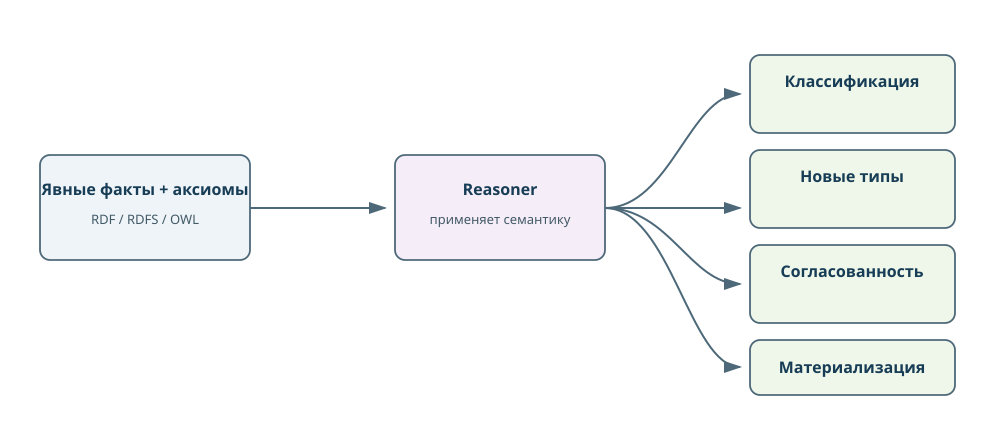

In [12]:
svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="430" viewBox="0 0 1000 430">
  <rect width="1000" height="430" fill="white"/>
  <defs>
    <marker id="arrR" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#4d6878"/>
    </marker>
  </defs>
  <style>
    .b{stroke:#4d6878;stroke-width:1.8}
    .t{font:700 16px sans-serif;fill:#173c55;text-anchor:middle}
    .s{font:13px sans-serif;fill:#425966;text-anchor:middle}
    .e{stroke:#4d6878;stroke-width:2;marker-end:url(#arrR)}
  </style>
  <rect x="40" y="155" width="210" height="105" rx="10" fill="#eef4f8" class="b"/>
  <text x="145" y="195" class="t">Явные факты + аксиомы</text>
  <text x="145" y="224" class="s">RDF / RDFS / OWL</text>
  <rect x="395" y="155" width="210" height="105" rx="10" fill="#f5edf8" class="b"/>
  <text x="500" y="195" class="t">Reasoner</text>
  <text x="500" y="224" class="s">применяет семантику</text>
  <rect x="750" y="55" width="205" height="78" rx="10" fill="#eef7ea" class="b"/>
  <text x="852" y="87" class="t">Классификация</text>
  <rect x="750" y="150" width="205" height="78" rx="10" fill="#eef7ea" class="b"/>
  <text x="852" y="182" class="t">Новые типы</text>
  <rect x="750" y="245" width="205" height="78" rx="10" fill="#eef7ea" class="b"/>
  <text x="852" y="277" class="t">Согласованность</text>
  <rect x="750" y="340" width="205" height="55" rx="10" fill="#eef7ea" class="b"/>
  <text x="852" y="373" class="t">Материализация</text>
  <path d="M250 208 H385" class="e"/>
  <path d="M605 208 C670 208,690 94,740 94" fill="none" class="e"/>
  <path d="M605 208 H740" class="e"/>
  <path d="M605 208 C670 208,690 284,740 284" fill="none" class="e"/>
  <path d="M605 208 C670 208,690 367,740 367" fill="none" class="e"/>
</svg>
"""
display(SVG(svg))


### 3.4. Различие логического вывода и валидации данных

Логический вывод и валидация решают различные задачи, хотя некоторые конструкции внешне могут быть похожи.

| Задача | Подходящий механизм |
|---|---|
| получить тип `Person` из типа `Student` | RDFS/OWL reasoner |
| получить обратную связь | OWL `inverseOf` |
| потребовать наличие значения в конкретной выгрузке | SHACL/ShEx или код приложения |
| проверить datatype, формат или диапазон значения | SHACL |
| обнаружить логический конфликт непересекающихся классов | OWL reasoner |
| ограничить число значений в проверяемом графе | SHACL |

RDFS и OWL определяют семантику утверждений и логические следствия. SHACL определяет требования к конкретному RDF-графу и проверяет соответствие данных заданному профилю.

Следующий раздел рассматривает SHACL как самостоятельный механизм валидации RDF-данных.


### 3.5. Валидация RDF-данных средствами SHACL

SHACL (Shapes Constraint Language) описывает условия, которым должен соответствовать проверяемый RDF-граф. Для этого используются два разных графа:

- **data graph** - фактические данные;
- **shapes graph** - правила проверки этих данных.

Рассмотрим простую ситуацию. В онтологии свойство `uni:courseCode` может быть объявлено свойством курса, но это само по себе не означает, что **каждый курс в конкретной выгрузке обязан иметь код**. 

Процесс проверки удобно представить так:

```text
data.ttl + shapes.ttl -> SHACL validator -> Validation Report
```

`ontology.ttl` при необходимости может использоваться валидатором как дополнительная схема, но его задача остаётся отличной от задачи shapes-графа.

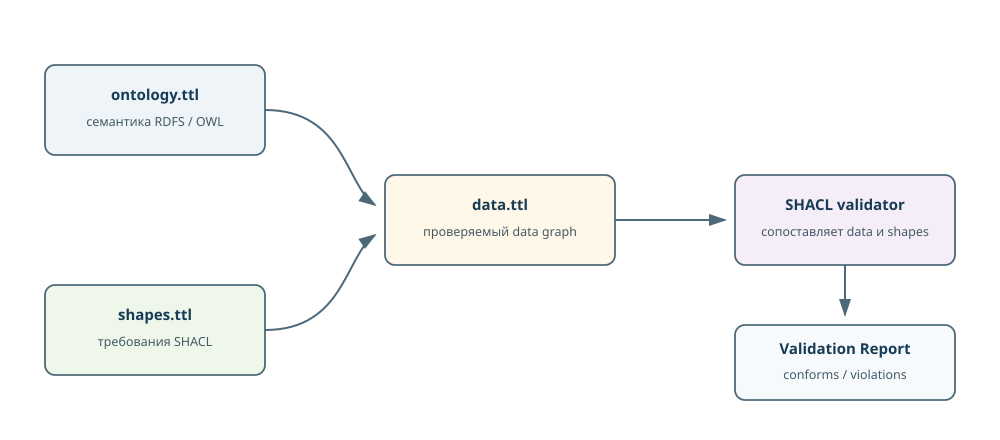

In [13]:
svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="1000" height="440" viewBox="0 0 1000 440">
  <rect width="1000" height="440" fill="white"/>
  <defs>
    <marker id="arrS" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#4d6878"/>
    </marker>
  </defs>
  <style>
    .b{stroke:#4d6878;stroke-width:1.8}
    .t{font:700 15px sans-serif;fill:#173c55;text-anchor:middle}
    .s{font:12.5px sans-serif;fill:#425966;text-anchor:middle}
    .e{stroke:#4d6878;stroke-width:2;marker-end:url(#arrS)}
  </style>
  <rect x="45" y="65" width="220" height="90" rx="10" fill="#eef4f8" class="b"/>
  <text x="155" y="100" class="t">ontology.ttl</text>
  <text x="155" y="126" class="s">семантика RDFS / OWL</text>

  <rect x="45" y="285" width="220" height="90" rx="10" fill="#eef7ea" class="b"/>
  <text x="155" y="320" class="t">shapes.ttl</text>
  <text x="155" y="346" class="s">требования SHACL</text>

  <rect x="385" y="175" width="230" height="90" rx="10" fill="#fff7e8" class="b"/>
  <text x="500" y="210" class="t">data.ttl</text>
  <text x="500" y="236" class="s">проверяемый data graph</text>

  <rect x="735" y="175" width="220" height="90" rx="10" fill="#f5edf8" class="b"/>
  <text x="845" y="210" class="t">SHACL validator</text>
  <text x="845" y="236" class="s">сопоставляет data и shapes</text>

  <rect x="735" y="325" width="220" height="75" rx="10" fill="#f7fafc" class="b"/>
  <text x="845" y="354" class="t">Validation Report</text>
  <text x="845" y="379" class="s">conforms / violations</text>

  <path d="M265 110 C345 110,345 185,375 205" fill="none" class="e"/>
  <path d="M265 330 C345 330,345 255,375 235" fill="none" class="e"/>
  <path d="M615 220 H725" class="e"/>
  <path d="M845 265 V315" class="e"/>
</svg>
"""
display(SVG(svg))


#### 3.5.1. Основные элементы SHACL-формы


| Элемент | Что задаёт |
|---|---|
| `sh:targetClass` | какие экземпляры проверяются |
| `sh:property` | блок требования к свойству |
| `sh:path` | проверяемый путь |
| `sh:minCount`, `sh:maxCount` | минимальное и максимальное число значений |
| `sh:datatype` | datatype литерала |
| `sh:class` | класс ресурса-значения |
| `sh:nodeKind` | вид RDF-узла |
| `sh:pattern` | формат строки |
| `sh:minInclusive`, `sh:maxInclusive` | числовые границы |
| `sh:message` | текст сообщения о нарушении |
| `sh:severity` | уровень результата |

Рассмотрим пример, где используется профиль класса `uni:Course`: курс должен иметь ровно один код, одно неотрицательное значение зачётных единиц и хотя бы одну связь с образовательной программой.


#### 3.5.2. Структура `CourseShape`: последовательность анализа логической структуры

С помощью SHACL-формы целесообразно анализировать логическую структуру документа/ файла от выбора целевых ресурсов к ограничениям отдельных свойств.

**Шаг 1. Определяем, какие ресурсы проверяются.** Для всех экземпляров `uni:Course` используется один `NodeShape`:

```turtle
uni:CourseShape a sh:NodeShape ;
    sh:targetClass uni:Course .
```

**Шаг 2. Задаём ограничения и количество кодов.** Следующий фрагмент означает, что в data graph должен быть ровно один `courseCode`:

```turtle
sh:path uni:courseCode ;
sh:minCount 1 ;
sh:maxCount 1 .
```

**Шаг 3. Проверяем datatype и формат кода.** Для строки дополнительно задаётся шаблон вида `ST-201`:

```turtle
sh:datatype xsd:string ;
sh:pattern "^[A-Z]{2}-[0-9]{3}$" .
```

**Шаг 4. Проверяем числовое значение.** Зачётные единицы должны быть `xsd:decimal` и не могут быть отрицательными:

```turtle
sh:path uni:credits ;
sh:datatype xsd:decimal ;
sh:minInclusive 0 .
```

**Шаг 5. Проверяем объектную связь.** Программа должна быть отдельным IRI-ресурсом соответствующего класса, а не строкой с названием:

```turtle
sh:path uni:partOfProgram ;
sh:nodeKind sh:IRI ;
sh:class uni:EducationalProgram .
```

Таким образом, один shape объединяет требования к наличию, количеству, типу и форме значений.

In [14]:
COURSE_SHAPES_TEMPLATE = r"""
@prefix uni: <https://example.org/university/> .
@prefix sh:  <http://www.w3.org/ns/shacl#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

uni:CourseShape a sh:NodeShape ;
    sh:targetClass uni:Course ;

    sh:property [
        sh:path uni:courseCode ;
        sh:minCount 1 ;
        sh:maxCount 1 ;
        sh:datatype xsd:string ;
        sh:pattern "^[A-Z]{2}-[0-9]{3}$" ;
        sh:message "У курса должен быть ровно один код вида ST-201."@ru
    ] ;

    sh:property [
        sh:path uni:credits ;
        sh:minCount 1 ;
        sh:maxCount 1 ;
        sh:datatype xsd:decimal ;
        sh:minInclusive 0 ;
        sh:message "Зачётные единицы должны быть одним неотрицательным числом xsd:decimal."@ru
    ] ;

    sh:property [
        sh:path uni:partOfProgram ;
        sh:minCount 1 ;
        sh:nodeKind sh:IRI ;
        sh:class uni:EducationalProgram ;
        sh:message "Курс должен ссылаться на образовательную программу через IRI."@ru
    ] .
"""

course_shapes_graph = parse_turtle_text(COURSE_SHAPES_TEMPLATE)

show_sparql_result(course_shapes_graph, r"""
PREFIX uni: <https://example.org/university/>
PREFIX sh:  <http://www.w3.org/ns/shacl#>

SELECT ?path ?minCount ?maxCount ?datatype ?nodeKind ?requiredClass ?pattern
WHERE {
  uni:CourseShape sh:property ?propertyShape .
  ?propertyShape sh:path ?path .
  OPTIONAL { ?propertyShape sh:minCount ?minCount }
  OPTIONAL { ?propertyShape sh:maxCount ?maxCount }
  OPTIONAL { ?propertyShape sh:datatype ?datatype }
  OPTIONAL { ?propertyShape sh:nodeKind ?nodeKind }
  OPTIONAL { ?propertyShape sh:class ?requiredClass }
  OPTIONAL { ?propertyShape sh:pattern ?pattern }
}
ORDER BY ?path
""")


path,minCount,maxCount,datatype,nodeKind,requiredClass,pattern
uni:courseCode,1,1,xsd:string,,,^[A-Z]{2}-[0-9]{3}$
uni:credits,1,1,xsd:decimal,,,
uni:partOfProgram,1,,,sh:IRI,uni:EducationalProgram,


#### 3.5.3. Проверка корректных и ошибочных данных

Рассмотрим ресурс, удовлетворяющий требованиям `CourseShape`, в котором один код нужного формата, числовые `credits` и ссылка на программу:

```turtle
uni:AppliedInformatics a uni:EducationalProgram .

uni:SemTech a uni:Course ;
    uni:courseCode "ST-201" ;
    uni:credits "3"^^xsd:decimal ;
    uni:partOfProgram uni:AppliedInformatics .
```

Для сопоставления рассмотрим ресурс, где преднамеренно нарушены требования: кодов два, `credits` имеет неверный datatype, связь `partOfProgram` отсутствует.

```turtle
uni:BrokenCourse a uni:Course ;
    uni:courseCode "ST-201", "KG-301" ;
    uni:credits "три" .
```

SHACL-валидатор должен вернуть `sh:conforms false` и отдельные `sh:ValidationResult` для найденных нарушений.

In [15]:
SHACL_DEMO_DATA = r"""
@prefix uni: <https://example.org/university/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

uni:AppliedInformatics a uni:EducationalProgram .

uni:GoodCourse a uni:Course ;
    uni:courseCode "ST-201" ;
    uni:credits "3"^^xsd:decimal ;
    uni:partOfProgram uni:AppliedInformatics .

uni:BrokenCourse a uni:Course ;
    uni:courseCode "ST-201", "KG-301" ;
    uni:credits "три" .
"""

shacl_demo_data_graph = parse_turtle_text(SHACL_DEMO_DATA)


def run_shacl_validation(data_graph, shapes_graph, ontology_graph=None):
    """Выполняет SHACL-валидацию через pySHACL и выводит результаты нарушений."""
    conforms, report_graph, report_text = shacl_validate(
        data_graph=data_graph,
        shacl_graph=shapes_graph,
        ont_graph=ontology_graph,
        inference="none",
        abort_on_first=False,
        allow_infos=True,
        allow_warnings=True,
        meta_shacl=False,
        advanced=False,
        debug=False,
    )

    print("SHACL conforms:", conforms)
    bind_common(report_graph)

    if conforms:
        print("Нарушения SHACL-ограничений не обнаружены.")
    else:
        show_sparql_result(report_graph, r"""
        PREFIX sh: <http://www.w3.org/ns/shacl#>
        SELECT ?focus ?path ?message ?severity
        WHERE {
          ?report a sh:ValidationReport ; sh:result ?result .
          ?result sh:focusNode ?focus ;
                  sh:resultSeverity ?severity .
          OPTIONAL { ?result sh:resultPath ?path }
          OPTIONAL { ?result sh:resultMessage ?message }
        }
        ORDER BY ?focus ?path
        """)

    return conforms, report_graph

demo_conforms, demo_report_graph = run_shacl_validation(
    shacl_demo_data_graph,
    course_shapes_graph,
)
print(
    "Интерпретация результата: conforms=False является ожидаемым, "
    "поскольку демонстрационный граф содержит ресурс BrokenCourse "
    "с преднамеренно нарушенными ограничениями."
)


SHACL conforms: False


focus,path,message,severity
uni:BrokenCourse,uni:courseCode,У курса должен быть ровно один код вида ST-201.,sh:Violation
uni:BrokenCourse,uni:credits,Зачётные единицы должны быть одним неотрицательным числом xsd:decimal.,sh:Violation
uni:BrokenCourse,uni:credits,Зачётные единицы должны быть одним неотрицательным числом xsd:decimal.,sh:Violation
uni:BrokenCourse,uni:partOfProgram,Курс должен ссылаться на образовательную программу через IRI.,sh:Violation


Интерпретация результата: conforms=False является ожидаемым, поскольку демонстрационный граф содержит ресурс BrokenCourse с преднамеренно нарушенными ограничениями.


#### 3.5.4. Различие назначений SHACL и OWL

SHACL и OWL могут использовать похожие по форме ограничения, однако их семантика и назначение различаются.

| Конструкция | Что она делает |
|---|---|
| `rdfs:domain uni:Course` | выводит тип субъекта при использовании свойства |
| `sh:targetClass uni:Course` | выбирает требуемые узлы для проверки |
| `owl:FunctionalProperty` | задаёт семантическую характеристику свойства |
| `sh:maxCount 1` | ограничивает число значений в текущем data graph |
| OWL cardinality | задаёт логическое ограничение класса в открытом мире |
| `sh:minCount` / `sh:maxCount` | проверяют количество фактически присутствующих значений |
| `rdfs:range` | позволяет вывести тип объекта |
| `sh:datatype`, `sh:class`, `sh:nodeKind` | проверяют представление значения |

Например, требование «в публикуемом каталоге у каждого курса ровно один код» естественно проверять через SHACL. Попытка заменить его только в виде ограничения строгой принадлежности меняет смысл задачи.

## 4. Публикация RDF-графа в модели Linked Data

Linked Data определяет подход к публикации структурированных данных в веб, при котором сущности получают устойчивые идентификаторы и могут быть связаны с ресурсами других наборов данных.

Существует четыре основных принципа Linked Data:

1. сущности именуются с помощью IRI;
2. для идентификаторов используются HTTP(S) IRI, доступные через веб;
3. при обращении к IRI предоставляется полезное представление ресурса на основе веб-стандартов;
4. данные содержат ссылки на другие IRI, обеспечивающие переход к связанным ресурсам.


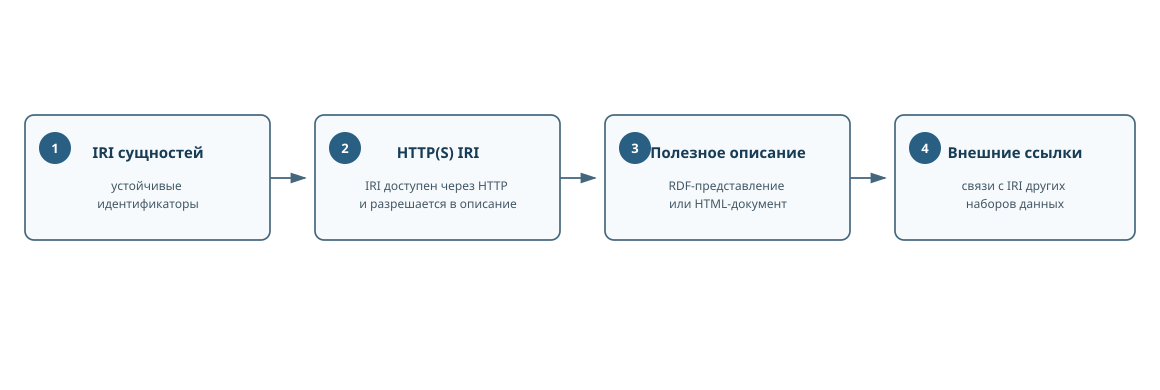

In [16]:
svg = r"""
<svg xmlns="http://www.w3.org/2000/svg" width="1160" height="390" viewBox="0 0 1160 390">
  <rect width="1160" height="390" fill="white"/>
  <defs>
    <marker id="arrL" markerWidth="10" markerHeight="10" refX="8" refY="3" orient="auto">
      <path d="M0,0 L0,6 L9,3 z" fill="#45677e"/>
    </marker>
  </defs>
  <style>
    .b{fill:#f7fafc;stroke:#45677e;stroke-width:1.7}
    .t{font:700 15px sans-serif;fill:#173c55;text-anchor:middle}
    .s{font:12px sans-serif;fill:#415765;text-anchor:middle}
    .e{stroke:#45677e;stroke-width:1.8;marker-end:url(#arrL)}
    .n{fill:#285f82}.nt{font:700 13px sans-serif;fill:white;text-anchor:middle}
  </style>

  <rect x="25" y="115" width="245" height="125" rx="9" class="b"/>
  <circle cx="55" cy="148" r="16" class="n"/><text x="55" y="153" class="nt">1</text>
  <text x="148" y="158" class="t">IRI сущностей</text>
  <text x="148" y="190" class="s">
    <tspan x="148" dy="0">устойчивые</tspan>
    <tspan x="148" dy="18">идентификаторы</tspan>
  </text>

  <rect x="315" y="115" width="245" height="125" rx="9" class="b"/>
  <circle cx="345" cy="148" r="16" class="n"/><text x="345" y="153" class="nt">2</text>
  <text x="438" y="158" class="t">HTTP(S) IRI</text>
  <text x="438" y="190" class="s">
    <tspan x="438" dy="0">IRI доступен через HTTP</tspan>
    <tspan x="438" dy="18">и разрешается в описание</tspan>
  </text>

  <rect x="605" y="115" width="245" height="125" rx="9" class="b"/>
  <circle cx="635" cy="148" r="16" class="n"/><text x="635" y="153" class="nt">3</text>
  <text x="728" y="158" class="t">Полезное описание</text>
  <text x="728" y="190" class="s">
    <tspan x="728" dy="0">RDF-представление</tspan>
    <tspan x="728" dy="18">или HTML-документ</tspan>
  </text>

  <rect x="895" y="115" width="240" height="125" rx="9" class="b"/>
  <circle cx="925" cy="148" r="16" class="n"/><text x="925" y="153" class="nt">4</text>
  <text x="1015" y="158" class="t">Внешние ссылки</text>
  <text x="1015" y="190" class="s">
    <tspan x="1015" dy="0">связи с IRI других</tspan>
    <tspan x="1015" dy="18">наборов данных</tspan>
  </text>

  <path d="M270 178 H305" class="e"/>
  <path d="M560 178 H595" class="e"/>
  <path d="M850 178 H885" class="e"/>
</svg>
"""
display(SVG(svg))


### 4.1. Разрешаемые IRI и HTTP-представления

В Linked Data HTTP(S) IRI используется не только как идентификатор, но и как адрес, через который клиент может получить представление ресурса.

Рассмотрим IRI курса:

```text
https://data.example.edu/id/course/semtech
```

Клиент может запросить RDF-представление, явно указав желаемый формат:

```http
Accept: text/turtle
```

Сервер, если формат поддерживается, отвечает соответствующим типом содержимого:

```http
Content-Type: text/turtle
```

Этот механизм называется согласованием содержимого. Тот же IRI может быть связан с HTML-представлением для человека и RDF-представлением для программы.

Важно различать предметную сущность и документ, который её описывает. Из этого различия естественно возникает отдельная схема IRI для терминов, сущностей и документов.

### 4.2. IRI терминов, сущностей и документов

При проектировании Linked Data рекомендуется различать идентификаторы терминов онтологии, предметных сущностей и документов, содержащих их описание.

Рассмотрим три группы идентификаторов:

```text
https://data.example.edu/ontology/Course
https://data.example.edu/ontology/studiesCourse

https://data.example.edu/id/course/semtech
https://data.example.edu/id/person/petrova-e

https://data.example.edu/doc/course/semtech
```

Первая группа идентифицирует **термины словаря**, вторая — **предметные сущности**, третья — **документы с описанием сущностей**.

Для каждого типа IRI необходимо определить устойчивую схему формирования и ожидаемое поведение при HTTP-доступе: какой ресурс идентифицируется, какое представление возвращается и требуется ли перенаправление.

После определения локальной системы идентификаторов можно задавать связи с внешними RDF-ресурсами.


### 4.3. Связывание с внешними RDF-ресурсами

Связывание наборов данных выполняется на уровне конкретных ресурсов. Для внешней связи необходимо установить, что именно связывается: идентичные сущности, близкие понятия, веб-описания или тематически связанные ресурсы.

Рассмотрим примеры:

```turtle
uni:ExampleUniversity owl:sameAs <https://www.wikidata.org/entity/Q123456> .
uni:Petrova schema:sameAs <https://orcid.org/0000-0000-0000-0000> .
uni:SemTech dcterms:subject <http://dbpedia.org/resource/Semantic_Web> .
```

В первом случае заявляется полное тождество, во втором указывается внешнее веб-описание сущности, в третьем задаётся тематическая связь. Эти отношения имеют различную семантику и не являются взаимозаменяемыми.

Корректное связывание включает выбор локального ресурса, поиск внешнего кандидата по устойчивым признакам, проверку его типа и контекста, выбор семантически подходящего отношения и только после этого добавление ссылки в RDF-граф.

In [17]:
show_table(
    ["Отношение", "Когда использовать", "Что нельзя подменять этим отношением"],
    [
        ["owl:sameAs", "два IRI обозначают одну и ту же сущность", "простую похожесть"],
        ["schema:sameAs", "веб-страница однозначно описывает объект", "произвольную тематическую ссылку"],
        ["skos:exactMatch", "понятия практически взаимозаменяемы", "тождество любых RDF-ресурсов"],
        ["skos:closeMatch", "понятия близки, но не полностью совпадают", "полную эквивалентность"],
        ["dcterms:subject", "ресурс связан с темой", "идентичность ресурса и темы"],
    ]
)


Отношение,Когда использовать,Что нельзя подменять этим отношением
owl:sameAs,два IRI обозначают одну и ту же сущность,простую похожесть
schema:sameAs,веб-страница однозначно описывает объект,произвольную тематическую ссылку
skos:exactMatch,понятия практически взаимозаменяемы,тождество любых RDF-ресурсов
skos:closeMatch,"понятия близки, но не полностью совпадают",полную эквивалентность
dcterms:subject,ресурс связан с темой,идентичность ресурса и темы


### 4.4. Этапы публикации связанного набора данных

Публикация Linked Data представляет собой последовательность практических действий. Сначала определяется состав публикуемых данных и исключаются сведения, не предназначенные для открытого доступа. Затем закрепляется устойчивая IRI-схема, данные представляются в RDF, проходят синтаксическую и SHACL-проверку, после чего настраивается HTTP-доступ и добавляются обоснованные внешние связи.

Связь основных этапов можно представить следующим образом:

```text
формальная схема -> RDF-данные -> валидация -> устойчивые IRI -> HTTP-доступ -> внешние ссылки
```

Такой порядок позволяет рассматривать публикацию не как отдельный формат файла, а как переход от локального RDF-графа к ресурсам, доступным и связанным в веб-среде.

Следующий подраздел посвящён проверкам, которые необходимо выполнить перед публикацией.


### 4.5. Контроль качества Linked Data перед публикацией

Перед публикацией недостаточно убедиться, что RDF-файл синтаксически корректен. Нужно проверить, что используемые IRI устойчивы, внешние связи выбраны по смыслу, данные актуальны и снабжены необходимыми метаданными.

Особенно важно избегать трёх ошибок:

1. менять IRI одного и того же ресурса при каждой выгрузке;
2. использовать `owl:sameAs` только потому, что объекты похожи по названию;
3. публиковать лишние персональные или служебные данные.

Следующая таблица кратко объединяет основные проверки, после чего начинается цельный пошаговый пример.


In [18]:
show_table(
    ["Слой", "Что проверяем перед переходом к примеру"],
    [
        ["RDFS", "классы, свойства, subClassOf, subPropertyOf, domain, range, аннотации"],
        ["OWL", "эквивалентность, несовместимость, характеристики свойств, ограничения"],
        ["Вывод", "явные факты, логические следствия, открытый мир, роль reasoner"],
        ["SHACL", "data graph, shapes graph, обязательность, количество, datatype, Validation Report"],
        ["Linked Data", "устойчивые IRI, HTTP-доступ, внешние связи, актуальность и качество данных"],
    ]
)


Слой,Что проверяем перед переходом к примеру
RDFS,"классы, свойства, subClassOf, subPropertyOf, domain, range, аннотации"
OWL,"эквивалентность, несовместимость, характеристики свойств, ограничения"
Вывод,"явные факты, логические следствия, открытый мир, роль reasoner"
SHACL,"data graph, shapes graph, обязательность, количество, datatype, Validation Report"
Linked Data,"устойчивые IRI, HTTP-доступ, внешние связи, актуальность и качество данных"


## 5. Пример

Исходная концептуальная модель считается заданной; основное внимание уделяется её формализации, проверке и подготовке к публикации.

Для контроля используются два требования:

- найти курс по коду `ST-201`;
- пройти цепочку `Teacher -> teachesCourse -> Course -> partOfProgram -> EducationalProgram`.


### Шаг 1. Подготовка файлов схемы, данных и SHACL-профиля

Формальная схема, экземпляры и правила валидации хранятся раздельно: схема описывает семантику, данные содержат факты, а shapes-граф задаёт требования к проверяемой выгрузке.

Используются три файла:

```text
ontology.ttl -> RDFS/OWL-схема
data.ttl     -> экземпляры и предметные факты
shapes.ttl   -> SHACL-профиль проверки data.ttl
```

Чтобы увидеть различие на конкретной записи, в `ontology.ttl` находится объявление свойства и его семантика:

```turtle
uni:studiesCourse a owl:ObjectProperty ;
    rdfs:subPropertyOf uni:participatesInLearning ;
    rdfs:domain uni:Student ;
    rdfs:range uni:Course .
```

А в `data.ttl` находится уже конкретный факт:

```turtle
uni:Anna uni:studiesCourse uni:SemTech .
```

Следующая ячейка создаёт **эталонные файлы примера** с именами `example_...`

In [19]:
example_ontology_filename = "example_university_ontology.ttl"
example_data_filename = "example_university_data.ttl"
example_shapes_filename = "example_university_shapes.ttl"

Path(example_ontology_filename).write_text(ONTOLOGY_TEMPLATE, encoding="utf-8")
Path(example_data_filename).write_text(DATA_TEMPLATE, encoding="utf-8")
Path(example_shapes_filename).write_text(COURSE_SHAPES_TEMPLATE, encoding="utf-8")
print("Созданы файлы образца:")
print(" -", example_ontology_filename)
print(" -", example_data_filename)
print(" -", example_shapes_filename)

download_button(example_ontology_filename, ONTOLOGY_TEMPLATE, mime="text/turtle")
download_button(example_data_filename, DATA_TEMPLATE, mime="text/turtle")
download_button(example_shapes_filename, COURSE_SHAPES_TEMPLATE, mime="text/turtle")


Созданы файлы образца:
 - example_university_ontology.ttl
 - example_university_data.ttl
 - example_university_shapes.ttl


### Шаг 2. Синтаксическая проверка RDF-файлов

До выполнения запросов нужно убедиться, что Turtle корректен синтаксически. Так ошибка парсинга означает, что дальнейшие выводы и запросы бессмысленны.

В следующей ячейке RDFLib независимо загружает `example_university_ontology.ttl`, `example_university_data.ttl` и `example_university_shapes.ttl`. После этого схема и данные объединяются только для выполнения SPARQL.

Ожидаемый результат - три сообщения об успешном разборе и таблица с числом троек в каждом графе.

In [20]:
example_schema_graph = bind_common(Graph())
example_schema_graph.parse(example_ontology_filename, format="turtle")

example_data_graph = bind_common(Graph())
example_data_graph.parse(example_data_filename, format="turtle")

example_shapes_graph = bind_common(Graph())
example_shapes_graph.parse(example_shapes_filename, format="turtle")

example_graph = clone_graph(example_schema_graph)
for triple in example_data_graph:
    example_graph.add(triple)

show_table(
    ["Файл/граф", "Результат", "Число троек"],
    [
        [example_ontology_filename, "Turtle разобран без ошибок", len(example_schema_graph)],
        [example_data_filename, "Turtle разобран без ошибок", len(example_data_graph)],
        [example_shapes_filename, "SHACL shapes разобраны как RDF без ошибок", len(example_shapes_graph)],
        ["объединённый граф", "готов к SPARQL", len(example_graph)],
    ]
)


Файл/граф,Результат,Число троек
example_university_ontology.ttl,Turtle разобран без ошибок,146
example_university_data.ttl,Turtle разобран без ошибок,61
example_university_shapes.ttl,SHACL shapes разобраны как RDF без ошибок,22
объединённый граф,готов к SPARQL,207


### Шаг 3. Поиск курса по коду

Первый запрос проверяет данные, а не логический вывод. Код курса записан явно в `data.ttl`, поэтому reasoner здесь не нужен.

Запрос ищет ресурс с `uni:courseCode "ST-201"` и его русскую метку. В следующей ячейке ожидается строка с курсом `uni:SemTech` и названием «Семантические технологии».

In [21]:
query_course_by_code = """
PREFIX uni:  <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?course ?label
WHERE {
  ?course uni:courseCode "ST-201" .
  OPTIONAL {
    ?course rdfs:label ?label .
    FILTER(LANG(?label) = "ru")
  }
}
"""
show_sparql_result(example_graph, query_course_by_code)


course,label
uni:SemTech,Семантические технологии


### Шаг 4. Запрос по цепочке «преподаватель -> курс -> программа»

В этом примере запрос должен связать три ресурса: преподавателя, курс и образовательную программу. Нужные факты уже присутствуют в `data.ttl`, поэтому результат снова не зависит от reasoner.

В следующей ячейке используется последовательность `teachesCourse` и `partOfProgram`. Ожидается как минимум строка «Елена Петрова -> Семантические технологии -> Прикладная информатика».

In [22]:
query_teacher_program = """
PREFIX uni:  <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?teacherName ?courseLabel ?programLabel
WHERE {
  ?teacher a uni:Teacher ;
           uni:fullName ?teacherName ;
           uni:teachesCourse ?course .

  ?course uni:partOfProgram ?program .

  OPTIONAL {
    ?course rdfs:label ?courseLabel .
    FILTER(LANG(?courseLabel) = "ru")
  }
  OPTIONAL {
    ?program rdfs:label ?programLabel .
    FILTER(LANG(?programLabel) = "ru")
  }
}
ORDER BY ?teacherName
"""
show_sparql_result(example_graph, query_teacher_program)


teacherName,courseLabel,programLabel
Елена Петрова,Семантические технологии,Прикладная информатика
Максим Сидоров,Графы знаний,Инженерия данных


### Шаг 5. Проверка иерархии классов

На этом шаге запрос обращается к схеме `ontology.ttl`, а не к экземплярам. Необходимо найти классы, связанные с `uni:Person` путём `rdfs:subClassOf+`.

В следующей ячейке используется **путь по свойствам** (SPARQL property path), который обходит иерархию схемы. Это показывает структуру классов, но ещё не добавляет новые `rdf:type` отдельным экземплярам.

In [23]:
show_sparql_result(example_schema_graph, """
PREFIX uni:  <https://example.org/university/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT DISTINCT ?class
WHERE {
  ?class rdfs:subClassOf+ uni:Person .
}
ORDER BY ?class
""")


class
uni:Student
uni:Teacher


### Шаг 6. Получение RDFS-следствий

Чтобы увидеть именно логическое следствие, добавим тестовый факт без явного типа субъекта:

```turtle
uni:NewStudent uni:studiesCourse uni:SemTech .
```

С учётом `domain`, `range`, `subClassOf` и `subPropertyOf` ожидаются новые утверждения: `NewStudent` получает тип `Student`, затем `Person`, а связь `studiesCourse` порождает более общее `participatesInLearning`.

Следующая ячейка демонстрирует эти правила и отдельно показывает полученные типы и результат `ASK` для более общего свойства.

In [24]:
rdfs_demo_graph = clone_graph(example_graph)
rdfs_demo_graph.add((UNI.NewStudent, UNI.studiesCourse, UNI.SemTech))

rdfs_closure = materialize_rdfs_subset(rdfs_demo_graph)

show_sparql_result(rdfs_closure, """
PREFIX uni: <https://example.org/university/>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>

SELECT ?type
WHERE {
  uni:NewStudent rdf:type ?type .
}
ORDER BY ?type
""")

print("Проверка более общего свойства:")
show_sparql_result(rdfs_closure, """
PREFIX uni: <https://example.org/university/>
ASK {
  uni:NewStudent uni:participatesInLearning uni:SemTech .
}
""")


type
foaf:Person
uni:Person
uni:Student
schema:Person


Проверка более общего свойства:
Результат ASK: True


### Шаг 7. Обратное свойство и конфликт непересекающихся классов

Для демонстрации OWL используются две аксиомы: `teachesCourse` связано с `isTaughtBy` через `owl:inverseOf`, а `Person` объявлен несовместимым с `Course`.

Первый результат содержит обратные факты вида `Course isTaughtBy Teacher`. После этого в тестовый граф добавляется тип `uni:SemTech a uni:Person`, создающий конфликт с типом `uni:Course`.

Следующая ячейка выполняет упрощённую обработку `inverseOf` и программно ищет ресурсы, одновременно попавшие в непересекающиеся классы. Тестовая ошибка в исходные файлы не сохраняется.

In [25]:
owl_demo_closure = materialize_rdfs_subset(example_graph, include_inverse=True)

show_sparql_result(owl_demo_closure, """
PREFIX uni: <https://example.org/university/>
SELECT ?course ?teacher
WHERE {
  ?course uni:isTaughtBy ?teacher .
}
ORDER BY ?course
""")

conflict_graph = clone_graph(owl_demo_closure)
conflict_graph.add((UNI.SemTech, RDF.type, UNI.Person))

conflicts = []
for class_a, class_b in conflict_graph.subject_objects(OWL.disjointWith):
    both = set(conflict_graph.subjects(RDF.type, class_a)) & set(conflict_graph.subjects(RDF.type, class_b))
    for resource in both:
        conflicts.append([
            term_text(resource, conflict_graph),
            term_text(class_a, conflict_graph),
            term_text(class_b, conflict_graph)
        ])

show_table(["Ресурс", "Несовместимый тип 1", "Несовместимый тип 2"], conflicts)


course,teacher
uni:KnowledgeGraphs,uni:Sidorov
uni:SemTech,uni:Petrova


Ресурс,Несовместимый тип 1,Несовместимый тип 2
uni:SemTech,uni:Person,uni:Course


### Шаг 8. Отсутствующие значения в условиях открытого мира

На этом шаге определяется множество курсов, для которых в текущем графе отсутствует `uni:credits`. Для проверки используется `FILTER NOT EXISTS`.

Важно заранее понимать интерпретацию результата: запрос показывает отсутствие тройки **в загруженном графе**, но не доказывает отрицательный факт в смысле OWL.

Следующая ячейка выполняет такой запрос. Если все эталонные курсы имеют `credits`, результат будет пустым, и это корректный ожидаемый результат.

In [26]:
show_sparql_result(example_graph, """
PREFIX uni: <https://example.org/university/>

SELECT ?course
WHERE {
  ?course a uni:Course .
  FILTER NOT EXISTS { ?course uni:credits ?credits }
}
ORDER BY ?course
""")


course


Запрос выполнен, строк результата нет.


### Шаг 9. SHACL-валидация корректного и ошибочного курса

На этом шаге проверяется не логический вывод, а соответствие конкретных RDF-данных требованиям, записанным в `shapes.ttl`.

Проверка выполняется последовательно.

1. **Выбирается SHACL-форма.** `CourseShape` применяется ко всем ресурсам класса `uni:Course` благодаря `sh:targetClass uni:Course`.
2. **Проверяются обязательные свойства.** Для курса требуется один `courseCode`, одно значение `credits` и как минимум одна связь `partOfProgram`.
3. **Проверяются типы и форма значений.** Код должен соответствовать заданному шаблону, `credits` должен иметь datatype `xsd:decimal`, а значение `partOfProgram` должно быть IRI ресурса класса `uni:EducationalProgram`.
4. **Валидируется корректный граф.** В `example_university_data.ttl` эталонные курсы удовлетворяют форме, поэтому ожидается `SHACL conforms: True`.
5. **Создаётся отдельный тестовый граф.** Исходные данные не изменяются: граф клонируется, и только в копию добавляется `uni:BrokenCourse`.
6. **В тестовый ресурс намеренно вводятся три нарушения:** два значения `courseCode`, строка `"три"` вместо `xsd:decimal` и отсутствие `partOfProgram`.
7. **pySHACL строит Validation Report.** Для каждого нарушения в отчёте можно определить проверяемый ресурс (`sh:focusNode`), путь свойства (`sh:resultPath`), уровень результата и поясняющее сообщение.

Таким образом, первая проверка подтверждает соответствие корректного набора профилю, а вторая демонстрирует, какие именно ограничения нарушает ошибочный ресурс. Значение `conforms=False` во второй проверке - ожидаемый результат


In [27]:
print("1) Проверка корректного example_university_data.ttl")
valid_shacl_result, _ = run_shacl_validation(
    example_data_graph,
    example_shapes_graph,
    ontology_graph=example_schema_graph,
)

print("\n2) Добавляем отдельный ошибочный курс только в тестовый граф")
broken_example_graph = clone_graph(example_data_graph)
broken_example_graph.add((UNI.BrokenCourse, RDF.type, UNI.Course))
broken_example_graph.add((UNI.BrokenCourse, UNI.courseCode, Literal("ST-201")))
broken_example_graph.add((UNI.BrokenCourse, UNI.courseCode, Literal("KG-301")))
broken_example_graph.add((UNI.BrokenCourse, UNI.credits, Literal("три")))

broken_shacl_result, _ = run_shacl_validation(
    broken_example_graph,
    example_shapes_graph,
    ontology_graph=example_schema_graph,
)


1) Проверка корректного example_university_data.ttl
SHACL conforms: True
Нарушения SHACL-ограничений не обнаружены.

2) Добавляем отдельный ошибочный курс только в тестовый граф
SHACL conforms: False


focus,path,message,severity
uni:BrokenCourse,uni:courseCode,У курса должен быть ровно один код вида ST-201.,sh:Violation
uni:BrokenCourse,uni:credits,Зачётные единицы должны быть одним неотрицательным числом xsd:decimal.,sh:Violation
uni:BrokenCourse,uni:credits,Зачётные единицы должны быть одним неотрицательным числом xsd:decimal.,sh:Violation
uni:BrokenCourse,uni:partOfProgram,Курс должен ссылаться на образовательную программу через IRI.,sh:Violation


После выполнения проверки `pySHACL` формирует **отдельный RDF-граф отчёта**, поэтому `focusNode`, `resultPath`, `resultMessage` и `resultSeverity` не задаются в `data.ttl` и не появляются произвольно. Это стандартные свойства SHACL, которыми валидатор описывает найденное нарушение.

Связь между `CourseShape` и Validation Report строится следующим образом.

1. `sh:targetClass uni:Course` определяет множество ресурсов, которые необходимо проверить. Каждый найденный экземпляр `uni:Course` последовательно становится **фокусным узлом** проверки. Если нарушение обнаружено у `uni:BrokenCourse`, в результате появляется:

```turtle
sh:focusNode uni:BrokenCourse
```

2. Внутри `CourseShape` каждое требование к свойству задаётся отдельным `sh:property`, а проверяемое свойство определяется через `sh:path`. Например:

```turtle
sh:path uni:courseCode ;
sh:minCount 1 ;
sh:maxCount 1 .
```

Если нарушается требование к `uni:courseCode`, валидатор переносит этот путь в результат проверки:

```turtle
sh:resultPath uni:courseCode
```

3. Конкретное нарушенное ограничение также фиксируется в отчёте. Например, наличие двух кодов при `sh:maxCount 1` соответствует компоненту ограничения `sh:MaxCountConstraintComponent`. Это позволяет определить не только свойство, но и **тип нарушенного правила**.

4. Текст, заданный в shape через `sh:message`, используется для описания результата, например, из фрагмента:

```turtle
sh:message "У курса должен быть ровно один код вида ST-201."@ru
```

в Validation Report появляется `sh:resultMessage` с соответствующим пояснением.

5. `sh:resultSeverity` показывает уровень результата. Если для shape явно не задано свойство `sh:severity`, используется стандартный уровень `sh:Violation`, поэтому в данном примере нарушение ограничения рассматривается как ошибка соответствия профилю.

Схематично один результат отчёта для `BrokenCourse` можно представить так:

```turtle
[] a sh:ValidationReport ;
   sh:conforms false ;
   sh:result [
       a sh:ValidationResult ;
       sh:focusNode uni:BrokenCourse ;
       sh:resultPath uni:courseCode ;
       sh:sourceConstraintComponent sh:MaxCountConstraintComponent ;
       sh:resultSeverity sh:Violation ;
       sh:resultMessage "У курса должен быть ровно один код вида ST-201."@ru
   ] .
```

Здесь внешний узел типа `sh:ValidationReport` описывает результат проверки всего графа, а каждый вложенный узел типа `sh:ValidationResult` соответствует **одному конкретному нарушению**.

Поэтому поля отчёта следует читать в следующей последовательности:

- `sh:focusNode` — **какой ресурс** не прошёл проверку;
- `sh:resultPath` — **какое свойство** проверялось;
- `sh:sourceConstraintComponent` — **какое ограничение SHACL** было нарушено;
- `sh:resultMessage` — **пояснение**, заданное автором shape;
- `sh:resultSeverity` — **уровень результата** проверки.

Нарушение SHACL означает несоответствие текущего **data graph** заданному профилю. Это не тождественно логической несогласованности OWL: SHACL проверяет фактически присутствующие данные, тогда как OWL описывает семантику и допустимые логические интерпретации.


### Шаг 10. Извлечение внешних IRI

Связность данных определяется наличием внешних IRI и корректностью выбранных отношений. В эталонном графе часть ресурсов связана с внешними источниками, например через `dcterms:subject`.

Следующий SPARQL-запрос ищет только те отношения, которые используются для связи с внешними IRI

In [28]:
show_sparql_result(example_graph, """
PREFIX owl:     <http://www.w3.org/2002/07/owl#>
PREFIX schema:  <https://schema.org/>
PREFIX skos:    <http://www.w3.org/2004/02/skos/core#>
PREFIX dcterms: <http://purl.org/dc/terms/>

SELECT ?resource ?predicate ?external
WHERE {
  VALUES ?predicate {
    owl:sameAs schema:sameAs skos:exactMatch skos:closeMatch dcterms:subject
  }
  ?resource ?predicate ?external .
  FILTER(isIRI(?external))
}
ORDER BY ?resource ?predicate
""")


resource,predicate,external
uni:KnowledgeGraphs,dcterms:subject,ns1:Knowledge_graph
uni:SemTech,dcterms:subject,ns1:Semantic_Web


Полученная строка результата интерпретируется как полноценная RDF-тройка «локальный ресурс → отношение → внешний ресурс». 

Значение внешней ссылки определяется используемым предикатом. 

`owl:sameAs` утверждает полное тождество ресурсов, `schema:sameAs` указывает на внешний ресурс, однозначно идентифицирующий ту же сущность, `skos:exactMatch` задаёт точное соответствие понятий, `skos:closeMatch` обозначает близкое, но не полное соответствие, а `dcterms:subject` связывает ресурс с его тематикой. 

Поэтому наличие внешнего IRI само по себе недостаточно: необходимо учитывать семантику отношения, которым этот IRI присоединён к локальному ресурсу.


## 6. Индивидуальное задание

Исходным материалом является `ontology_draft.ttl`, содержащий концептуальную модель предметной области вашего варианта. На его основе необходимо выполнить формализацию, продемонстрировать логические следствия, провести SHACL-валидацию и подготовить элементы Linked Data.

### Последовательность выполнения

1. На основе черновика подготовить `ontology.ttl` и `data.ttl`, отделив формальную схему от экземпляров.
2. Уточнить типы свойств: использовать `owl:ObjectProperty` и `owl:DatatypeProperty` там, где это соответствует модели.
3. Для иерархий применить `rdfs:subClassOf` и при необходимости `rdfs:subPropertyOf`; пояснить ожидаемые следствия.
4. Для выбранных свойств задать `rdfs:domain` и `rdfs:range` только там, где возникающая типизация действительно желательна.
5. Покажзать минимум три RDFS-следствия на данных своего варианта и отделить их от явно записанных троек.
6. Добавить минимум одну содержательно оправданную OWL-аксиому из рассмотренных конструкций и объяснить её логический смысл.
7. Реализовать один предметный запрос SPARQL с цепочкой минимум из двух отношений. Дополнительно выполнить запрос к схеме и запрос с проверкой отсутствующего значения.
8. Создать `shapes.ttl` минимум с одним `sh:NodeShape`. Использовать не менее трёх разных ограничений, включая ограничение количества и проверку типа, класса или вида RDF-узла.
9. Подготовить один корректный и один намеренно ошибочный ресурс и объяснить полученный SHACL Validation Report.
10. Для одного ресурса спроектировать публикационный HTTP(S) IRI и указать различие между IRI сущности и IRI документа о ней.
11. Добавить минимум две внешние связи. Для каждой обосновать выбор `owl:sameAs`, `schema:sameAs`, `skos:exactMatch`, `skos:closeMatch`, `dcterms:subject` или другое отношение.


In [29]:
N_STUDENTS = 80

# Номер варианта определяет предметную область и дополнительный фокус формализации.
domains = [
    ("Электронная библиотека", ["Произведение", "Издание", "Экземпляр", "Автор", "Читатель"]),
    ("Научная конференция", ["Мероприятие", "Секция", "Доклад", "Автор", "Рецензия"]),
    ("Музейная коллекция", ["Объект", "Коллекция", "Автор", "Материал", "Выставка"]),
    ("Городской транспорт", ["Маршрут", "Остановка", "Рейс", "Транспортное средство", "Оператор"]),
    ("Интернет-магазин", ["Товар", "Предложение", "Продавец", "Цена", "Категория"]),
    ("Учебная платформа", ["Курс", "Модуль", "Задание", "Попытка", "Пользователь"]),
]

formalization_focuses = [
    ("Формальная связь с внешним классом",
     "Для двух локальных классов задайте обоснованный rdfs:subClassOf к внешнему классу и покажите следствие через иерархию.",
     "SPARQL должен вывести локальный класс, внешний родительский класс и хотя бы один экземпляр, который достигает более общего типа."),
    ("Формализация ролей человека",
     "Формализуйте две совместимые роли одного ресурса и общий родительский класс. Не объявляйте роли непересекающимися без предметного основания.",
     "После RDFS-вывода один ресурс должен получать общий родительский тип из обеих ролей."),
    ("Контроль семантики domain и range",
     "Для двух свойств обоснуйте выбор rdfs:domain и rdfs:range и покажите, какие типы ресурсов выводятся при использовании этих свойств.",
     "Проверка должна показать исходный факт и типы, полученные после применения правил domain и range."),
    ("Семантика внешней связи",
     "Для двух внешних IRI выберите разные по смыслу отношения связи и обоснуйте, почему это не автоматическое owl:sameAs.",
     "SPARQL должен вывести локальный ресурс, тип связи и внешний IRI."),
    ("Абстрактный объект и его реализация",
     "Формально свяжите абстрактную сущность с конкретной реализацией во времени и задайте минимум один временной datatype.",
     "SPARQL должен пройти от абстрактного ресурса к реализации и вывести временное значение."),
    ("Промежуточная сущность для сложного отношения",
     "Одно отношение с собственными атрибутами представьте отдельным ресурсом и свяжите минимум двумя ObjectProperty и одним DatatypeProperty.",
     "SPARQL должен пройти через промежуточный ресурс и вернуть его собственный атрибут."),
    ("OWL-совместимость классов",
     "Добавьте одну оправданную аксиому disjointWith или equivalentClass и подготовьте тестовый случай, демонстрирующий её смысл.",
     "Покажите ожидаемый вывод или конфликт отдельно от SHACL-валидации."),
    ("HTTP IRI и представления ресурса",
     "Для одного ресурса задайте IRI сущности и отдельный IRI документа, опишите ожидаемое RDF-представление и HTML-документ с описанием ресурса.",
     "Проверка должна явно различать идентификатор сущности и URL документа/выгрузки."),
    ("SHACL для многоязычных и строковых значений",
     "Создайте shape, который проверяет обязательное строковое значение и его формат; для многоязычного поля поясните работу языковых литералов.",
     "Покажите один корректный и один нарушающий shape ресурс."),
    ("SHACL для объектной связи",
     "Создайте shape для обязательной объектной связи: значение должно быть IRI и экземпляром заданного класса.",
     "Ошибочный ресурс должен содержать строку или ресурс неверного класса и давать нарушение валидации."),
    ("SPARQL по цепочке отношений",
     "Возьмите один ранее сформулированный компетентностный вопрос и реализуйте его через цепочку минимум из двух объектных отношений.",
     "SELECT должен возвращать осмысленный результат и не зависеть от случайных строковых совпадений."),
    ("Материализация RDFS",
     "Покажите совместную работу subClassOf, domain/range и при необходимости subPropertyOf на одном тестовом факте.",
     "Сравните набор явных типов до материализации и типы/отношения после применения правил."),
    ("Открытый мир и отсутствующие данные",
     "Создайте запрос FILTER NOT EXISTS и отдельно объясните, что именно можно и нельзя заключить из его результата.",
     "Проверка должна содержать результат SPARQL и корректную интерпретацию в условиях открытого мира."),
    ("OWL и SHACL для одного требования",
     "Возьмите одно предметное правило и покажите две разные постановки: семантическую через OWL и проверочную через SHACL.",
     "Объясните, почему OWL-аксиома и SHACL-ограничение не являются взаимозаменяемыми."),
]

variant_records = []
variant_rows = []
for i in range(N_STUDENTS):
    domain, entities = domains[i % len(domains)]
    focus_title, sem2_task, control = formalization_focuses[(i // len(domains)) % len(formalization_focuses)]
    record = {
        "variant": i + 1,
        "domain": domain,
        "entities": ", ".join(entities),
        "focus": focus_title,
        "sem2_task": sem2_task,
        "control": control,
    }
    variant_records.append(record)
    variant_rows.append([
        record["variant"], record["domain"], record["entities"],
        record["focus"], record["sem2_task"], record["control"]
    ])

assert len(variant_records) == 80
assert len(set((r["domain"], r["focus"]) for r in variant_records)) == 80

print("Сформировано 80 уникальных индивидуальных вариантов.")
show_table(
    ["Вариант", "Предметная область", "Базовые сущности",
     "Фокус формализации", "Дополнительное условие", "Контроль результата"],
    variant_rows
)

Сформировано 80 уникальных индивидуальных вариантов.


Вариант,Предметная область,Базовые сущности,Фокус формализации,Дополнительное условие,Контроль результата
1,Электронная библиотека,"Произведение, Издание, Экземпляр, Автор, Читатель",Формальная связь с внешним классом,Для двух локальных классов задайте обоснованный rdfs:subClassOf к внешнему классу и покажите следствие через иерархию.,"SPARQL должен вывести локальный класс, внешний родительский класс и хотя бы один экземпляр, который достигает более общего типа."
2,Научная конференция,"Мероприятие, Секция, Доклад, Автор, Рецензия",Формальная связь с внешним классом,Для двух локальных классов задайте обоснованный rdfs:subClassOf к внешнему классу и покажите следствие через иерархию.,"SPARQL должен вывести локальный класс, внешний родительский класс и хотя бы один экземпляр, который достигает более общего типа."
3,Музейная коллекция,"Объект, Коллекция, Автор, Материал, Выставка",Формальная связь с внешним классом,Для двух локальных классов задайте обоснованный rdfs:subClassOf к внешнему классу и покажите следствие через иерархию.,"SPARQL должен вывести локальный класс, внешний родительский класс и хотя бы один экземпляр, который достигает более общего типа."
4,Городской транспорт,"Маршрут, Остановка, Рейс, Транспортное средство, Оператор",Формальная связь с внешним классом,Для двух локальных классов задайте обоснованный rdfs:subClassOf к внешнему классу и покажите следствие через иерархию.,"SPARQL должен вывести локальный класс, внешний родительский класс и хотя бы один экземпляр, который достигает более общего типа."
5,Интернет-магазин,"Товар, Предложение, Продавец, Цена, Категория",Формальная связь с внешним классом,Для двух локальных классов задайте обоснованный rdfs:subClassOf к внешнему классу и покажите следствие через иерархию.,"SPARQL должен вывести локальный класс, внешний родительский класс и хотя бы один экземпляр, который достигает более общего типа."
6,Учебная платформа,"Курс, Модуль, Задание, Попытка, Пользователь",Формальная связь с внешним классом,Для двух локальных классов задайте обоснованный rdfs:subClassOf к внешнему классу и покажите следствие через иерархию.,"SPARQL должен вывести локальный класс, внешний родительский класс и хотя бы один экземпляр, который достигает более общего типа."
7,Электронная библиотека,"Произведение, Издание, Экземпляр, Автор, Читатель",Формализация ролей человека,Формализуйте две совместимые роли одного ресурса и общий родительский класс. Не объявляйте роли непересекающимися без предметного основания.,После RDFS-вывода один ресурс должен получать общий родительский тип из обеих ролей.
8,Научная конференция,"Мероприятие, Секция, Доклад, Автор, Рецензия",Формализация ролей человека,Формализуйте две совместимые роли одного ресурса и общий родительский класс. Не объявляйте роли непересекающимися без предметного основания.,После RDFS-вывода один ресурс должен получать общий родительский тип из обеих ролей.
9,Музейная коллекция,"Объект, Коллекция, Автор, Материал, Выставка",Формализация ролей человека,Формализуйте две совместимые роли одного ресурса и общий родительский класс. Не объявляйте роли непересекающимися без предметного основания.,После RDFS-вывода один ресурс должен получать общий родительский тип из обеих ролей.
10,Городской транспорт,"Маршрут, Остановка, Рейс, Транспортное средство, Оператор",Формализация ролей человека,Формализуйте две совместимые роли одного ресурса и общий родительский класс. Не объявляйте роли непересекающимися без предметного основания.,После RDFS-вывода один ресурс должен получать общий родительский тип из обеих ролей.


### Получение индивидуального варианта

В таблице представлены 80 вариантов. Каждый вариант задаёт предметную область, базовые сущности и дополнительное требование к формализации, выводу, SHACL или Linked Data.

Чтобы вывести условия одного варианта отдельно, укажите его номер в следующей ячейке.


In [30]:
VARIANT_NUMBER = 57  # укажите свой номер от 1 до 80

if not 1 <= VARIANT_NUMBER <= 80:
    raise ValueError("Номер варианта должен быть от 1 до 80.")

v = variant_records[VARIANT_NUMBER - 1]
show_table(
    ["Поле", "Задание"],
    [
        ["Вариант", v["variant"]],
        ["Предметная область", v["domain"]],
        ["Базовые сущности", v["entities"]],
        ["Фокус формализации", v["focus"]],
        ["Дополнительное условие", v["sem2_task"]],
        ["Контроль результата", v["control"]],
        ["Обязательный SHACL", f"Создать NodeShape для ключевого класса {v['entities'].split(', ')[0]}: минимум одно обязательное свойство, одно ограничение количества и одну проверку datatype/class/nodeKind. Показать корректный и ошибочный ресурс."],
    ]
)

Поле,Задание
Вариант,57
Предметная область,Музейная коллекция
Базовые сущности,"Объект, Коллекция, Автор, Материал, Выставка"
Фокус формализации,SHACL для объектной связи
Дополнительное условие,Создайте shape для обязательной объектной связи: значение должно быть IRI и экземпляром заданного класса.
Контроль результата,Ошибочный ресурс должен содержать строку или ресурс неверного класса и давать нарушение валидации.
Обязательный SHACL,"Создать NodeShape для ключевого класса Объект: минимум одно обязательное свойство, одно ограничение количества и одну проверку datatype/class/nodeKind. Показать корректный и ошибочный ресурс."


## 7. Решение индивидуального задания: вариант 57

**Предметная область:** музейная коллекция.  
**Базовые сущности:** объект, коллекция, автор, материал, выставка.  
**Специальный фокус:** обязательная объектная связь должна вести на IRI экземпляра заданного класса.

Исходный `ontology_draft.ttl` разделён на три самостоятельных артефакта:

- `ontology.ttl` — классы, свойства, `domain`/`range`, иерархии и OWL-аксиомы;
- `data.ttl` — экземпляры, включая корректный и намеренно ошибочный объект;
- `shapes.ttl` — проверочные ограничения SHACL.

Такое разделение не смешивает семантическую модель, факты и правила контроля качества.

In [31]:
from rdflib import Graph, Namespace
from rdflib.namespace import RDF, RDFS, OWL, DCTERMS
from pyshacl import validate

MUS = Namespace("https://example.org/museum/ontology/")
MID = Namespace("https://example.org/museum/id/")

ontology57 = bind_common(Graph())
ontology57.bind("mus", MUS)
ontology57.bind("id", MID)
ontology57.parse("ontology.ttl", format="turtle")

data57 = bind_common(Graph())
data57.bind("mus", MUS)
data57.bind("id", MID)
data57.parse("data.ttl", format="turtle")

shapes57 = bind_common(Graph())
shapes57.bind("mus", MUS)
shapes57.parse("shapes.ttl", format="turtle")

print(f"ontology.ttl: {len(ontology57)} троек")
print(f"data.ttl: {len(data57)} троек")
print(f"shapes.ttl: {len(shapes57)} троек")
assert len(ontology57) > 0 and len(data57) > 0 and len(shapes57) > 0

ontology.ttl: 110 троек
data.ttl: 39 троек
shapes.ttl: 27 троек


### 7.1. Формальная схема RDFS/OWL

Все отношения между ресурсами объявлены как `owl:ObjectProperty`, а свойства литеральных значений — как `owl:DatatypeProperty`. Иерархия `Artwork → MuseumObject → MuseumEntity` позволяет получать более общие типы. Свойство `createdBy` является под-свойством `dcterms:creator`.

`domain` и `range` здесь означают правила логического вывода, а не ограничения ввода. Например, факт `x mus:createdBy y` позволяет вывести, что `x` — музейный объект, а `y` — автор.

Содержательно оправданная OWL-аксиома — `mus:hasMember owl:inverseOf mus:memberOfCollection`: если коллекция содержит объект, то объект входит в эту коллекцию. Дополнительно `inventoryNumber` объявлен функциональным, поскольку в модели у музейного объекта не должно быть двух различных значений инвентарного номера. Проверку количества выполняет SHACL, тогда как OWL описывает семантику свойства.

In [32]:
# Минимальный тест отделяет явно записанные тройки от RDFS-следствий.
inference_test = clone_graph(ontology57)
inference_test.add((MID.TestArtwork, RDF.type, MUS.Artwork))
inference_test.add((MID.TestArtwork, MUS.createdBy, MID.TestCreator))

explicit_test_triples = {
    (MID.TestArtwork, RDF.type, MUS.Artwork),
    (MID.TestArtwork, MUS.createdBy, MID.TestCreator),
}
closure57 = materialize_rdfs_subset(inference_test)

expected_inferences = [
    (MID.TestArtwork, RDF.type, MUS.MuseumObject),          # subClassOf
    (MID.TestArtwork, RDF.type, MUS.MuseumEntity),          # транзитивная иерархия
    (MID.TestCreator, RDF.type, MUS.Creator),                # range(createdBy)
    (MID.TestArtwork, DCTERMS.creator, MID.TestCreator),     # subPropertyOf
]

rows = []
for triple in expected_inferences:
    rows.append([
        term_text(triple[0], closure57),
        term_text(triple[1], closure57),
        term_text(triple[2], closure57),
        "явная" if triple in explicit_test_triples else "выведенная",
        triple in closure57,
    ])
show_table(["Субъект", "Предикат", "Объект", "Статус", "Получено"], rows)
assert all(triple in closure57 for triple in expected_inferences)
assert all(triple not in explicit_test_triples for triple in expected_inferences)

Субъект,Предикат,Объект,Статус,Получено
ns1:TestArtwork,rdf:type,ns2:MuseumObject,выведенная,True
ns1:TestArtwork,rdf:type,ns2:MuseumEntity,выведенная,True
ns1:TestCreator,rdf:type,ns2:Creator,выведенная,True
ns1:TestArtwork,dcterms:creator,ns1:TestCreator,выведенная,True


Получены четыре неявные тройки, то есть требование минимум о трёх RDFS-следствиях выполнено. `domain`/`range` используются только там, где такая типизация желательна: объект, указанный субъектом `createdBy`, считается музейным объектом, а значение свойства — автором.

### 7.2. Предметный, схемный и диагностический SPARQL-запросы

Компетентностный вопрос: **какой музейный объект показывается на какой выставке и какая организация её проводит?** Цепочка содержит два объектных отношения: `shownAt / organizedBy`.

In [33]:
query_graph57 = clone_graph(ontology57)
for triple in data57:
    query_graph57.add(triple)

show_sparql_result(query_graph57, """
PREFIX mus: <https://example.org/museum/ontology/>
PREFIX dcterms: <http://purl.org/dc/terms/>
SELECT ?object ?objectTitle ?exhibition ?organization WHERE {
  ?object mus:shownAt ?exhibition .
  ?exhibition mus:organizedBy ?organization .
  OPTIONAL { ?object dcterms:title ?objectTitle . FILTER(LANG(?objectTitle) = "ru") }
}
ORDER BY ?object
""")

object,objectTitle,exhibition,organization
ns1:BlackSquare1930,Чёрный квадрат (1930),ns1:RussianAvantGardeExhibition,ns1:DemoMuseum


In [34]:
# Запрос к схеме: локальные классы и их непосредственные родители.
show_sparql_result(ontology57, """
PREFIX mus: <https://example.org/museum/ontology/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
SELECT ?class ?parent WHERE {
  ?class a rdfs:Class ; rdfs:subClassOf ?parent .
  FILTER(STRSTARTS(STR(?class), STR(mus:)))
}
ORDER BY ?class ?parent
""")

class,parent
mus:Agent,mus:MuseumEntity
mus:Artwork,mus:MuseumObject
mus:Collection,mus:MuseumEntity
mus:Creator,mus:Agent
mus:Creator,schema:Person
mus:Document,mus:MuseumObject
mus:Exhibition,mus:MuseumEntity
mus:Exhibition,schema:Event
mus:MaterialConcept,skos:Concept
mus:MaterialConcept,mus:MuseumEntity


In [35]:
# В загруженном графе ищем музейные объекты без даты поступления.
show_sparql_result(query_graph57, """
PREFIX mus: <https://example.org/museum/ontology/>
SELECT ?object WHERE {
  ?object a mus:MuseumObject .
  FILTER NOT EXISTS { ?object mus:acquisitionDate ?date }
}
ORDER BY ?object
""")

object
ns1:BrokenObject


`FILTER NOT EXISTS` сообщает лишь, что в текущем RDF-графе нет тройки с датой поступления. В условиях открытого мира это не доказывает, что дата не существует в действительности или в другом источнике.

### 7.3. SHACL: обязательная объектная связь

`MuseumObjectShape` проверяет:

1. обязательное название и его количество;
2. обязательный уникальный инвентарный номер, тип и формат;
3. обязательную связь `createdBy`: значение — IRI и экземпляр `mus:Creator`;
4. обязательную связь `madeOf`: значение — IRI и экземпляр `mus:MaterialConcept`.

Валидация ниже запускается отдельно для корректного и ошибочного ресурсов, чтобы результат был нагляден. Режим `inference="none"` выбран намеренно: иначе RDFS-правило `range` само присвоило бы любому значению `madeOf` класс `MaterialConcept` и скрыло бы именно ту ошибку исходных данных, которую должен обнаружить `sh:class`.

In [36]:
def resource_subgraph(source, subject):
    graph = bind_common(Graph())
    graph.bind("mus", MUS)
    graph.bind("id", MID)
    for triple in source.triples((subject, None, None)):
        graph.add(triple)
    # Для sh:class нужны типы объектов значений.
    for _, predicate, value in list(graph):
        if predicate in (MUS.createdBy, MUS.madeOf):
            for triple in source.triples((value, RDF.type, None)):
                graph.add(triple)
    return graph

valid_only = resource_subgraph(data57, MID.BlackSquare1930)
invalid_only = resource_subgraph(data57, MID.BrokenObject)

valid_conforms, _, valid_report = validate(
    valid_only, shacl_graph=shapes57, ont_graph=ontology57,
    inference="none", abort_on_first=False,
)
invalid_conforms, invalid_report_graph, invalid_report = validate(
    invalid_only, shacl_graph=shapes57, ont_graph=ontology57,
    inference="none", abort_on_first=False,
)

print("Корректный ресурс соответствует shape:", valid_conforms)
print("Ошибочный ресурс соответствует shape:", invalid_conforms)
print("\nValidation Report для ошибочного ресурса:\n")
print(invalid_report)

assert valid_conforms is True
assert invalid_conforms is False

Корректный ресурс соответствует shape: True
Ошибочный ресурс соответствует shape: False

Validation Report для ошибочного ресурса:

Validation Report
Conforms: False
Results (5):
Constraint Violation in ClassConstraintComponent (http://www.w3.org/ns/shacl#ClassConstraintComponent):
	Severity: sh:Violation
	Source Shape: [ sh:class mus:Creator ; sh:message Literal("Автор обязателен, должен быть IRI и экземпляром mus:Creator.", lang=ru) ; sh:minCount Literal("1", datatype=xsd:integer) ; sh:nodeKind sh:IRI ; sh:path mus:createdBy ]
	Focus Node: id:BrokenObject
	Value Node: Literal("неизвестный автор")
	Result Path: mus:createdBy
	Message: Автор обязателен, должен быть IRI и экземпляром mus:Creator.
Constraint Violation in ClassConstraintComponent (http://www.w3.org/ns/shacl#ClassConstraintComponent):
	Severity: sh:Violation
	Source Shape: [ sh:class mus:MaterialConcept ; sh:message Literal("Материал обязателен, должен быть IRI и экземпляром mus:MaterialConcept.", lang=ru) ; sh:minCount Li

В отчёте для `id:BrokenObject` ожидаются нарушения: отсутствует `dcterms:title`; инвентарный номер не соответствует шаблону; `createdBy` содержит строковый литерал вместо IRI автора; `madeOf` указывает на коллекцию, а не на экземпляр `MaterialConcept`. SHACL проверяет полноту и форму конкретного графа и не заменяет OWL/RDFS-вывод.

### 7.4. Linked Data и внешние связи

Для публикации ресурса используются разные IRI:

- IRI сущности: `https://example.org/museum/id/BlackSquare1930`;
- IRI документа: `https://example.org/museum/doc/BlackSquare1930`;
- RDF-представление: `https://example.org/museum/doc/BlackSquare1930.ttl`.

IRI сущности идентифицирует сам музейный объект, а IRI документа — информационный ресурс с его описанием. Сервер может отвечать на IRI сущности перенаправлением `303 See Other` или выбирать RDF/HTML по `Accept`.

В `data.ttl` добавлены две внешние связи:

- `schema:sameAs` ведёт к карточке Wikidata, принятой в этой учебной модели как идентификатор того же объекта; более сильное `owl:sameAs` не используется, чтобы не переносить автоматически все утверждения и идентичность из внешнего графа;
- `dcterms:subject` ведёт к теме `Russian_avant-garde` в DBpedia: это тематическая классификация, а не тождество музейного объекта и внешнего понятия.

In [37]:
show_sparql_result(data57, """
PREFIX schema: <https://schema.org/>
PREFIX dcterms: <http://purl.org/dc/terms/>
SELECT ?resource ?relation ?externalIRI WHERE {
  VALUES ?relation { schema:sameAs dcterms:subject }
  ?resource ?relation ?externalIRI .
  FILTER(isIRI(?externalIRI))
}
ORDER BY ?resource ?relation
""")

resource,relation,externalIRI
id:BlackSquare1930,dcterms:subject,ns1:Russian_avant-garde
id:BlackSquare1930,schema:sameAs,ns2:Q27970882


### 7.5. Итог

Для варианта 57 построена формальная музейная онтология, экземпляры отделены от схемы, показаны RDFS-следствия и OWL-семантика, выполнены три вида SPARQL-запросов, SHACL отличает корректный ресурс от ошибочного, а публикационные IRI и внешние связи имеют явно объяснённый смысл.